In [4]:
# Required dependencies: rdkit, openmm, openff-toolkit, pandas
import json
from pathlib import Path
import pandas as pd
import numpy as np

# RDKit imports
from rdkit import Chem
from rdkit.Chem import AllChem, rdDistGeom

# OpenFF and OpenMM imports
from openff.toolkit.topology import Molecule as OFFMolecule
from openff.toolkit.typing.engines.smirnoff import ForceField as OFFForeField
import openmm as mm
from openmm import unit

In [5]:
# Reproducibility settings and path configuration
CONFIG = {
    "num_conformers": 30, # Range: 20-40
    "random_seed": 20261019,
    "initial_minimization": "MMFF94",
    "fallback_minimization": "UFF",
    "openmm_force_field": "openff-2.1.0.offxml", # Sage small-molecule force field
    "input_csv": "/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exercise_metabolites.csv",
    "output_dir": "/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs"
}

out_dir = Path(CONFIG["output_dir"])
out_dir.mkdir(parents=True, exist_ok=True)

# Generate Run Manifest
with open(out_dir / "run_manifest.json", "w") as f:
    json.dump(CONFIG, f, indent=4)
print(f"Run manifest saved to {out_dir / 'run_manifest.json'}")

Run manifest saved to /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs/run_manifest.json


In [6]:
# Read curated metabolites and identify valid/invalid SMILES
df = pd.read_csv(CONFIG["input_csv"])

valid_mols = []
failed_records = []

for idx, row in df.iterrows():
    # Fallback to standard column names if dataset varies
    name = row.get('metabolite', f"mol_{idx}")
    smiles = row.get('smiles', None)
    
    if pd.isna(smiles):
        failed_records.append({"metabolite": name, "reason": "Missing SMILES"})
        continue
        
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        failed_records.append({"metabolite": name, "smiles": smiles, "reason": "Invalid SMILES parsing"})
    else:
        mol.SetProp("_Name", str(name))
        valid_mols.append({"name": name, "smiles": smiles, "rdkit_mol": mol})

print(f"Validated {len(valid_mols)} molecules. Failed {len(failed_records)} molecules.")

Validated 52 molecules. Failed 13 molecules.


In [7]:
# Initialize OpenFF force field once
off_forcefield = OFFForeField(CONFIG["openmm_force_field"])

def generate_rdkit_conformers(mol, num_confs, seed):
    """Generate 3D conformers and perform initial RDKit minimization."""
    mol = Chem.AddHs(mol)
    
    # ETKDGv3 parameters
    params = rdDistGeom.ETKDGv3()
    params.randomSeed = seed
    params.enforceChirality = True
    params.useRandomCoords = True 
    
    cids = rdDistGeom.EmbedMultipleConfs(mol, numConfs=num_confs, params=params)
    
    conformer_data = []
    for cid in cids:
        # Prioritize MMFF94, fallback to UFF
        if AllChem.MMFFHasAllMoleculeParams(mol):
            ff = AllChem.MMFFGetMoleculeForceField(mol, AllChem.MMFFGetMoleculeProperties(mol), confId=cid)
            ff_name = "MMFF94"
        else:
            ff = AllChem.UFFGetMoleculeForceField(mol, confId=cid)
            ff_name = "UFF"
            
        if ff:
            ff.Minimize()
            energy = ff.CalcEnergy()
        else:
            energy = np.nan
            ff_name = "Failed"
            
        conformer_data.append({"cid": cid, "rdkit_energy": energy, "rdkit_ff": ff_name})
        
    return mol, conformer_data

def refine_with_openmm(rdkit_mol, cid):
    """Parameterize and refine a specific conformer using OpenMM and OpenFF."""
    try:
        # Isolate single conformer for OpenFF parameterization
        single_conf_mol = Chem.Mol(rdkit_mol)
        single_conf_mol.RemoveAllConformers()
        single_conf_mol.AddConformer(rdkit_mol.GetConformer(cid), assignId=True)
        
        # Convert to OpenFF Molecule
        off_mol = OFFMolecule.from_rdkit(single_conf_mol, allow_undefined_stereo=True)
        
        # Setup OpenMM System
        topology = off_mol.to_topology()
        system = off_forcefield.create_openmm_system(topology)
        
        integrator = mm.VerletIntegrator(1.0 * unit.femtoseconds)
        context = mm.Context(system, integrator)
        context.setPositions(off_mol.conformers[0])
        
        # Minimize (Vacuum)
        mm.LocalEnergyMinimizer.minimize(context, tolerance=10*unit.kilojoules_per_mole/unit.nanometer)
        state = context.getState(getEnergy=True, getPositions=True)
        
        # Extract refined positions and energy
        positions = state.getPositions(asNumpy=True).value_in_unit(unit.angstrom)
        refined_energy = state.getPotentialEnergy().value_in_unit(unit.kilojoules_per_mole)
        
        # Update RDKit molecule coordinates
        conf = single_conf_mol.GetConformer(0)
        for i in range(single_conf_mol.GetNumAtoms()):
            x, y, z = positions[i]
            conf.SetAtomPosition(i, (x, y, z))
            
        return single_conf_mol, refined_energy, "Success"
        
    except Exception as e:
        return None, np.nan, f"OpenMM Error: {str(e)}"

In [8]:
ensemble_writer = Chem.SDWriter(str(out_dir / "conformers.sdf"))
rep_writer = Chem.SDWriter(str(out_dir / "representative_conformers.sdf"))
qc_records = []

for item in valid_mols:
    name = item["name"]
    base_mol = item["rdkit_mol"]
    
    # 1. RDKit Generation
    mol_3d, rdkit_data = generate_rdkit_conformers(
        base_mol, 
        CONFIG["num_conformers"], 
        CONFIG["random_seed"]
    )
    
    best_energy = float('inf')
    best_mol = None
    
    # 2. OpenMM Refinement Loop
    for conf_info in rdkit_data:
        cid = conf_info["cid"]
        
        refined_mol, omm_energy, status = refine_with_openmm(mol_3d, cid)
        
        # Compile QC Data
        qc_row = {
            "metabolite": name,
            "conformer_id": cid,
            "rdkit_forcefield": conf_info["rdkit_ff"],
            "rdkit_energy_kcal_mol": conf_info["rdkit_energy"],
            "openmm_status": status,
            "openmm_energy_kj_mol": omm_energy
        }
        qc_records.append(qc_row)
        
        # Save to Ensemble SDF if refinement succeeded
        if refined_mol and status == "Success":
            refined_mol.SetProp("OpenMM_Energy", str(omm_energy))
            refined_mol.SetProp("Conformer_ID", str(cid))
            ensemble_writer.write(refined_mol)
            
            # Track lowest energy conformer for the representative file
            if omm_energy < best_energy:
                best_energy = omm_energy
                best_mol = refined_mol
                
    # Save Representative Conformer
    if best_mol:
        best_mol.SetProp("Rep_Selection", "Lowest_OpenMM_Energy")
        rep_writer.write(best_mol)

ensemble_writer.close()
rep_writer.close()

# 3. Export Tables
pd.DataFrame(qc_records).to_csv(out_dir / "conformer_energies_qc.csv", index=False)
if failed_records:
    pd.DataFrame(failed_records).to_csv(out_dir / "failed_molecules.csv", index=False)

print("Pipeline execution complete. SDF and QC files generated.")

Pipeline execution complete. SDF and QC files generated.


In [11]:
from openff.toolkit.utils.toolkits import RDKitToolkitWrapper

def refine_with_openmm(rdkit_mol, cid):
    """
    Parameterize and refine a specific conformer using OpenMM and OpenFF.
    Pre-assigns Gasteiger partial charges via RDKit to bypass missing AmberTools/am1bcc.
    """
    single_conf_mol = Chem.Mol(rdkit_mol)
    single_conf_mol.RemoveAllConformers()
    single_conf_mol.AddConformer(rdkit_mol.GetConformer(cid), assignId=True)
    
    try:
        # Convert to OpenFF Molecule
        off_mol = OFFMolecule.from_rdkit(single_conf_mol, allow_undefined_stereo=True)
        
        # Pre-assign Gasteiger charges via RDKit to avoid AM1-BCC ToolkitWrapper failure
        off_mol.assign_partial_charges(
            partial_charge_method="gasteiger",
            toolkit_registry=RDKitToolkitWrapper()
        )
        
        # Build OpenMM system with pre-assigned charges
        topology = off_mol.to_topology()
        system = off_forcefield.create_openmm_system(topology)
        
        integrator = mm.VerletIntegrator(1.0 * unit.femtoseconds)
        context = mm.Context(system, integrator)
        context.setPositions(off_mol.conformers[0])
        
        # Minimize in vacuum
        mm.LocalEnergyMinimizer.minimize(context, tolerance=10*unit.kilojoules_per_mole/unit.nanometer)
        state = context.getState(getEnergy=True, getPositions=True)
        
        positions = state.getPositions(asNumpy=True).value_in_unit(unit.angstrom)
        refined_energy = state.getPotentialEnergy().value_in_unit(unit.kilojoules_per_mole)
        
        # Update RDKit coordinates with OpenMM optimized geometry
        conf = single_conf_mol.GetConformer(0)
        for i in range(single_conf_mol.GetNumAtoms()):
            x, y, z = positions[i]
            conf.SetAtomPosition(i, (x, y, z))
            
        return single_conf_mol, refined_energy, "Success"
        
    except Exception as e:
        # Fallback: Return original RDKit conformer if OpenMM fails
        return single_conf_mol, np.nan, f"OpenMM Fallback: {str(e)}"

In [12]:
ensemble_writer = Chem.SDWriter(str(out_dir / "conformers.sdf"))
rep_writer = Chem.SDWriter(str(out_dir / "representative_conformers.sdf"))
qc_records = []

for item in valid_mols:
    name = item["name"]
    base_mol = item["rdkit_mol"]
    
    # 1. Generate RDKit conformer ensemble
    mol_3d, rdkit_data = generate_rdkit_conformers(
        base_mol, 
        CONFIG["num_conformers"], 
        CONFIG["random_seed"]
    )
    
    best_energy = float('inf')
    best_mol = None
    
    # 2. Refine and write to SDF
    for conf_info in rdkit_data:
        cid = conf_info["cid"]
        
        refined_mol, omm_energy, status = refine_with_openmm(mol_3d, cid)
        
        qc_row = {
            "metabolite": name,
            "conformer_id": cid,
            "rdkit_forcefield": conf_info["rdkit_ff"],
            "rdkit_energy_kcal_mol": conf_info["rdkit_energy"],
            "openmm_status": status,
            "openmm_energy_kj_mol": omm_energy
        }
        qc_records.append(qc_row)
        
        # Always write valid 3D structure to SDF (OpenMM or RDKit fallback)
        if refined_mol is not None:
            refined_mol.SetProp("Conformer_ID", str(cid))
            refined_mol.SetProp("Refinement_Status", status)
            if not np.isnan(omm_energy):
                refined_mol.SetProp("OpenMM_Energy_kJ_mol", str(omm_energy))
            else:
                refined_mol.SetProp("RDKit_Energy_kcal_mol", str(conf_info["rdkit_energy"]))
                
            ensemble_writer.write(refined_mol)
            
            # Select lowest energy conformer for representative export
            comp_energy = omm_energy if not np.isnan(omm_energy) else conf_info["rdkit_energy"]
            if comp_energy < best_energy:
                best_energy = comp_energy
                best_mol = refined_mol

    if best_mol is not None:
        rep_writer.write(best_mol)

ensemble_writer.close()
rep_writer.close()

# Export metadata and QC reports
pd.DataFrame(qc_records).to_csv(out_dir / "conformer_energies_qc.csv", index=False)
if failed_records:
    pd.DataFrame(failed_records).to_csv(out_dir / "failed_molecules.csv", index=False)

print(f"Pipeline complete. Outputs written to {out_dir}")

Pipeline complete. Outputs written to /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs


In [ ]:
# Required dependencies: py3Dmol, ipywidgets
import py3Dmol
from rdkit.Chem import rdMolAlign
import ipywidgets as widgets
from IPython.display import display

def visualize_conformer_ensemble(metabolite_name, sdf_path):
    supplier = Chem.SDMolSupplier(str(sdf_path), removeHs=False)
    
    # Isolate conformers for the target metabolite
    conformers = [mol for mol in supplier if mol is not None and mol.GetProp("_Name") == metabolite_name]
    
    if not conformers:
        print(f"No conformers found for {metabolite_name}.")
        return
        
    # Combine into a single RDKit Mol object to calculate 3D alignment
    ensemble_mol = Chem.Mol(conformers[0])
    ensemble_mol.RemoveAllConformers()
    
    for i, mol in enumerate(conformers):
        conf = mol.GetConformer(0)
        ensemble_mol.AddConformer(conf, assignId=True)
        
    # Align all conformers to the representative structure (Model 0)
    rdMolAlign.AlignMolConformers(ensemble_mol)
    
    # Initialize py3Dmol viewer
    view = py3Dmol.view(width=900, height=500)
    
    for i in range(ensemble_mol.GetNumConformers()):
        mb = Chem.MolToMolBlock(ensemble_mol, confId=i)
        view.addModel(mb, 'sdf')
        
    # Base styling for the ensemble (thin sticks, default elemental colors)
    view.setStyle({'stick': {'radius': 0.1}})
    
    # Highlight the representative/lowest-energy conformer (Model 0) with thicker green carbons
    view.setStyle({'model': 0}, {'stick': {'colorscheme': 'greenCarbon', 'radius': 0.25}})
    
    view.zoomTo()
    print(f"Displaying {ensemble_mol.GetNumConformers()} aligned conformers for {metabolite_name}")
    print("Green: Representative (Lowest OpenMM Energy) | Standard: Ensemble")
    
    return view.show()

# Read the QC manifest to populate the dropdown menu dynamically
try:
    df_qc = pd.read_csv(out_dir / "conformer_energies_qc.csv")
    unique_metabolites = df_qc['metabolite'].unique()

    # Generate the interactive UI
    dropdown = widgets.interact(
        visualize_conformer_ensemble, 
        metabolite_name=widgets.Dropdown(options=unique_metabolites, description='Metabolite:'),
        sdf_path=widgets.fixed(out_dir / "conformers.sdf")
    )
except FileNotFoundError:
    print("Run the OpenMM pipeline in Cell 5 first to generate the SDF and QC outputs.")

interactive(children=(Dropdown(description='Metabolite:', options=('mol_0', 'mol_1', 'mol_2', 'mol_3', 'mol_4'…

In [13]:
import openmm as mm
import openmm.app as app
from openmm import unit
from openff.toolkit.topology import Molecule as OFFMolecule, Topology as OFFTopology
from openff.toolkit.utils.toolkits import RDKitToolkitWrapper

def refine_with_openmm_solvated(rdkit_mol, cid, padding_nm=1.0):
    """
    Solvates a small-molecule conformer in a TIP3P water box, assigns Gasteiger 
    charges via RDKit, and performs energy minimization in explicit solvent.
    
    Parameters:
    -----------
    rdkit_mol : rdkit.Chem.Mol
        Molecule containing 3D conformers.
    cid : int
        Conformer ID to refine.
    padding_nm : float
        Box padding distance in nanometers (default: 1.0 nm / 10 Angstroms).
    """
    # Isolate single conformer
    single_conf_mol = Chem.Mol(rdkit_mol)
    single_conf_mol.RemoveAllConformers()
    single_conf_mol.AddConformer(rdkit_mol.GetConformer(cid), assignId=True)
    
    try:
        # 1. Convert to OpenFF Molecule & pre-assign Gasteiger partial charges
        off_mol = OFFMolecule.from_rdkit(single_conf_mol, allow_undefined_stereo=True)
        off_mol.assign_partial_charges(
            partial_charge_method="gasteiger",
            toolkit_registry=RDKitToolkitWrapper()
        )
        
        # 2. Extract OpenMM Topology and Positions for Solute
        openmm_top = off_mol.to_topology().to_openmm()
        openmm_pos = off_mol.conformers[0].to_openmm()
        
        # 3. Solvate solute using OpenMM Modeller with TIP3P water
        modeller = app.Modeller(openmm_top, openmm_pos)
        ff_water = app.ForceField('tip3p.xml')
        
        modeller.addSolvent(
            ff_water,
            model='tip3p',
            padding=padding_nm * unit.nanometers,
            boxShape='cube',
            neutralize=True # Adds counter-ions (Na+/Cl-) if molecule carries a net charge
        )
        
        # 4. Construct OpenFF Topology for Solvated System
        water_mol = OFFMolecule.from_smiles('O')
        na_ion = OFFMolecule.from_smiles('[Na+]')
        cl_ion = OFFMolecule.from_smiles('[Cl-]')
        
        solvated_off_top = OFFTopology.from_openmm(
            modeller.topology,
            unique_molecules=[off_mol, water_mol, na_ion, cl_ion]
        )
        
        # 5. Create OpenMM System with Sage force field (includes PME nonbonded method)
        system = off_forcefield.create_openmm_system(
            solvated_off_top,
            charge_from_molecules=[off_mol]
        )
        
        # 6. Local Energy Minimization in Explicit Solvent
        integrator = mm.VerletIntegrator(1.0 * unit.femtoseconds)
        context = mm.Context(system, integrator)
        context.setPositions(modeller.positions)
        
        mm.LocalEnergyMinimizer.minimize(
            context, 
            tolerance=10.0 * unit.kilojoules_per_mole / unit.nanometer
        )
        
        # 7. Extract Minimized State
        state = context.getState(getEnergy=True, getPositions=True)
        all_positions = state.getPositions(asNumpy=True).value_in_unit(unit.angstrom)
        solvated_energy = state.getPotentialEnergy().value_in_unit(unit.kilojoules_per_mole)
        
        # 8. Strip solvent: Extract updated positions for solute atoms only
        n_solute_atoms = single_conf_mol.GetNumAtoms()
        solute_positions = all_positions[:n_solute_atoms]
        
        conf = single_conf_mol.GetConformer(0)
        for i in range(n_solute_atoms):
            x, y, z = solute_positions[i]
            conf.SetAtomPosition(i, (x, y, z))
            
        n_waters = (len(all_positions) - n_solute_atoms) // 3
        return single_conf_mol, solvated_energy, n_waters, "Solvated_Success"
        
    except Exception as e:
        return single_conf_mol, np.nan, 0, f"Solvation Error: {str(e)}"

In [14]:
ensemble_writer = Chem.SDWriter(str(out_dir / "conformers.sdf"))
rep_writer = Chem.SDWriter(str(out_dir / "representative_conformers.sdf"))
qc_records = []

for item in valid_mols:
    name = item["name"]
    base_mol = item["rdkit_mol"]
    
    # 1. RDKit ETKDGv3 Conformer Generation
    mol_3d, rdkit_data = generate_rdkit_conformers(
        base_mol, 
        CONFIG["num_conformers"], 
        CONFIG["random_seed"]
    )
    
    best_energy = float('inf')
    best_mol = None
    
    # 2. Solvated OpenMM Refinement Loop
    for conf_info in rdkit_data:
        cid = conf_info["cid"]
        
        refined_mol, omm_energy, n_waters, status = refine_with_openmm_solvated(
            mol_3d, 
            cid, 
            padding_nm=1.0
        )
        
        qc_row = {
            "metabolite": name,
            "conformer_id": cid,
            "rdkit_forcefield": conf_info["rdkit_ff"],
            "rdkit_energy_kcal_mol": conf_info["rdkit_energy"],
            "openmm_status": status,
            "solvated_energy_kj_mol": omm_energy,
            "num_water_molecules": n_waters
        }
        qc_records.append(qc_row)
        
        if refined_mol is not None:
            refined_mol.SetProp("Conformer_ID", str(cid))
            refined_mol.SetProp("Refinement_Status", status)
            refined_mol.SetProp("Solvent_Model", "TIP3P")
            
            if not np.isnan(omm_energy):
                refined_mol.SetProp("Solvated_Energy_kJ_mol", str(omm_energy))
                refined_mol.SetProp("Explicit_Water_Count", str(n_waters))
            else:
                refined_mol.SetProp("RDKit_Energy_kcal_mol", str(conf_info["rdkit_energy"]))
                
            ensemble_writer.write(refined_mol)
            
            # Select lowest-energy solvated structure for representative export
            comp_energy = omm_energy if not np.isnan(omm_energy) else conf_info["rdkit_energy"]
            if comp_energy < best_energy:
                best_energy = comp_energy
                best_mol = refined_mol

    if best_mol is not None:
        best_mol.SetProp("Rep_Selection", "Lowest_Solvated_Energy")
        rep_writer.write(best_mol)

ensemble_writer.close()
rep_writer.close()

# Export metadata and QC reports
pd.DataFrame(qc_records).to_csv(out_dir / "conformer_energies_qc.csv", index=False)
if failed_records:
    pd.DataFrame(failed_records).to_csv(out_dir / "failed_molecules.csv", index=False)

print(f"Solvated pipeline complete. Outputs written to {out_dir}")

Solvated pipeline complete. Outputs written to /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs


In [15]:
ensemble_writer = Chem.SDWriter(str(out_dir / "conformers.sdf"))
rep_writer = Chem.SDWriter(str(out_dir / "representative_conformers.sdf"))
qc_records = []

for item in valid_mols:
    name = item["name"]
    base_mol = item["rdkit_mol"]
    
    # 1. RDKit ETKDGv3 Conformer Generation
    mol_3d, rdkit_data = generate_rdkit_conformers(
        base_mol, 
        CONFIG["num_conformers"], 
        CONFIG["random_seed"]
    )
    
    best_energy = float('inf')
    best_mol = None
    
    # 2. Solvated OpenMM Refinement Loop
    for conf_info in rdkit_data:
        cid = conf_info["cid"]
        
        refined_mol, omm_energy, n_waters, status = refine_with_openmm_solvated(
            mol_3d, 
            cid, 
            padding_nm=1.0
        )
        
        qc_row = {
            "metabolite": name,
            "conformer_id": cid,
            "rdkit_forcefield": conf_info["rdkit_ff"],
            "rdkit_energy_kcal_mol": conf_info["rdkit_energy"],
            "openmm_status": status,
            "solvated_energy_kj_mol": omm_energy,
            "num_water_molecules": n_waters
        }
        qc_records.append(qc_row)
        
        if refined_mol is not None:
            refined_mol.SetProp("Conformer_ID", str(cid))
            refined_mol.SetProp("Refinement_Status", status)
            refined_mol.SetProp("Solvent_Model", "TIP3P")
            
            if not np.isnan(omm_energy):
                refined_mol.SetProp("Solvated_Energy_kJ_mol", str(omm_energy))
                refined_mol.SetProp("Explicit_Water_Count", str(n_waters))
            else:
                refined_mol.SetProp("RDKit_Energy_kcal_mol", str(conf_info["rdkit_energy"]))
                
            ensemble_writer.write(refined_mol)
            
            # Select lowest-energy solvated structure for representative export
            comp_energy = omm_energy if not np.isnan(omm_energy) else conf_info["rdkit_energy"]
            if comp_energy < best_energy:
                best_energy = comp_energy
                best_mol = refined_mol

    if best_mol is not None:
        best_mol.SetProp("Rep_Selection", "Lowest_Solvated_Energy")
        rep_writer.write(best_mol)

ensemble_writer.close()
rep_writer.close()

# Export metadata and QC reports
pd.DataFrame(qc_records).to_csv(out_dir / "conformer_energies_qc.csv", index=False)
if failed_records:
    pd.DataFrame(failed_records).to_csv(out_dir / "failed_molecules.csv", index=False)

print(f"Solvated pipeline complete. Outputs written to {out_dir}")

Solvated pipeline complete. Outputs written to /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs


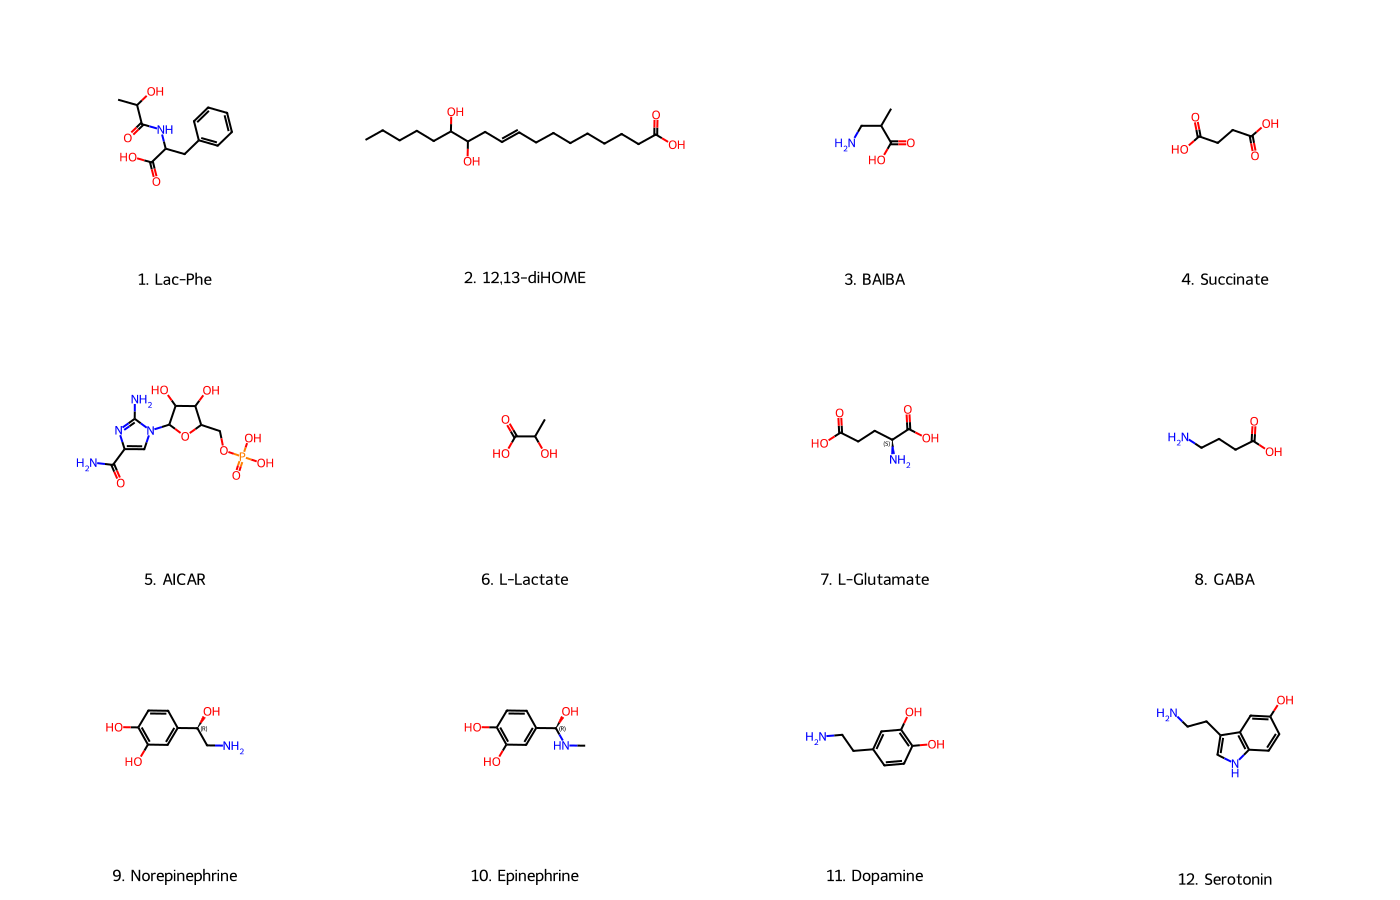

AttributeError: 'Image' object has no attribute 'save'

In [19]:
# Required dependencies: rdkit, IPython
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import display

# 1. Define the 12 Exerkines dataset
exerkine_data = [
    ("1. Lac-Phe", "CC(O)C(=O)NC(Cc1ccccc1)C(=O)O"),
    ("2. 12,13-diHOME", "CCCCCC(O)C(O)CC=CCCCCCCCC(=O)O"),
    ("3. BAIBA", "CC(CN)C(=O)O"),
    ("4. Succinate", "C(CC(=O)O)C(=O)O"),
    ("5. AICAR", "NC(=O)c1cn(C2OC(COP(=O)(O)O)C(O)C2O)c(N)n1"),
    ("6. L-Lactate", "CC(O)C(=O)O"),
    ("7. L-Glutamate", "N[C@@H](CCC(=O)O)C(=O)O"),
    ("8. GABA", "NCCCC(=O)O"),
    ("9. Norepinephrine", "NC[C@H](O)c1ccc(O)c(O)c1"),
    ("10. Epinephrine", "CN[C@H](O)c1ccc(O)c(O)c1"),
    ("11. Dopamine", "NCCc1ccc(O)c(O)c1"),
    ("12. Serotonin", "NCCc1c[nH]c2ccc(O)cc12")
]

# 2. Parse SMILES and generate 2D coordinates
mols = []
labels = []

for name, smiles in exerkine_data:
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        Chem.rdDepictor.Compute2DCoords(mol)
        mols.append(mol)
        labels.append(name)

# 3. Configure high-resolution Drawing Options
draw_options = rdMolDraw2D.MolDrawOptions()
draw_options.addAtomIndices = False
draw_options.addStereoAnnotation = True
draw_options.bondLineWidth = 2.0
draw_options.legendFontSize = 16
draw_options.minFontSize = 12

# 4. Render SVG grid
svg_grid = Draw.MolsToGridImage(
    mols,
    molsPerRow=4,
    subImgSize=(350, 300),
    legends=labels,
    useSVG=True,
    drawOptions=draw_options
)

# 5. Display directly in Jupyter (RDKit SVG object implements _repr_svg_)
display(svg_grid)

# 6. Extract raw SVG text string and write to file
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
out_dir.mkdir(parents=True, exist_ok=True)

# Safely extract string data across different RDKit wrapper versions
svg_string = svg_grid.data if hasattr(svg_grid, 'data') else str(svg_grid)

# Save SVG vector image
with open(out_dir / "exerkines_2d_grid.svg", "w", encoding="utf-8") as f:
    f.write(svg_string)

# Save PNG raster image (300 DPI equivalent)
png_img = Draw.MolsToGridImage(
    mols,
    molsPerRow=4,
    subImgSize=(500, 400),
    legends=labels,
    useSVG=False,
    drawOptions=draw_options
)
png_img.save(out_dir / "exerkines_2d_grid.png")

print(f"Saved publication-quality renders to:\n - {out_dir / 'exerkines_2d_grid.svg'}\n - {out_dir / 'exerkines_2d_grid.png'}")

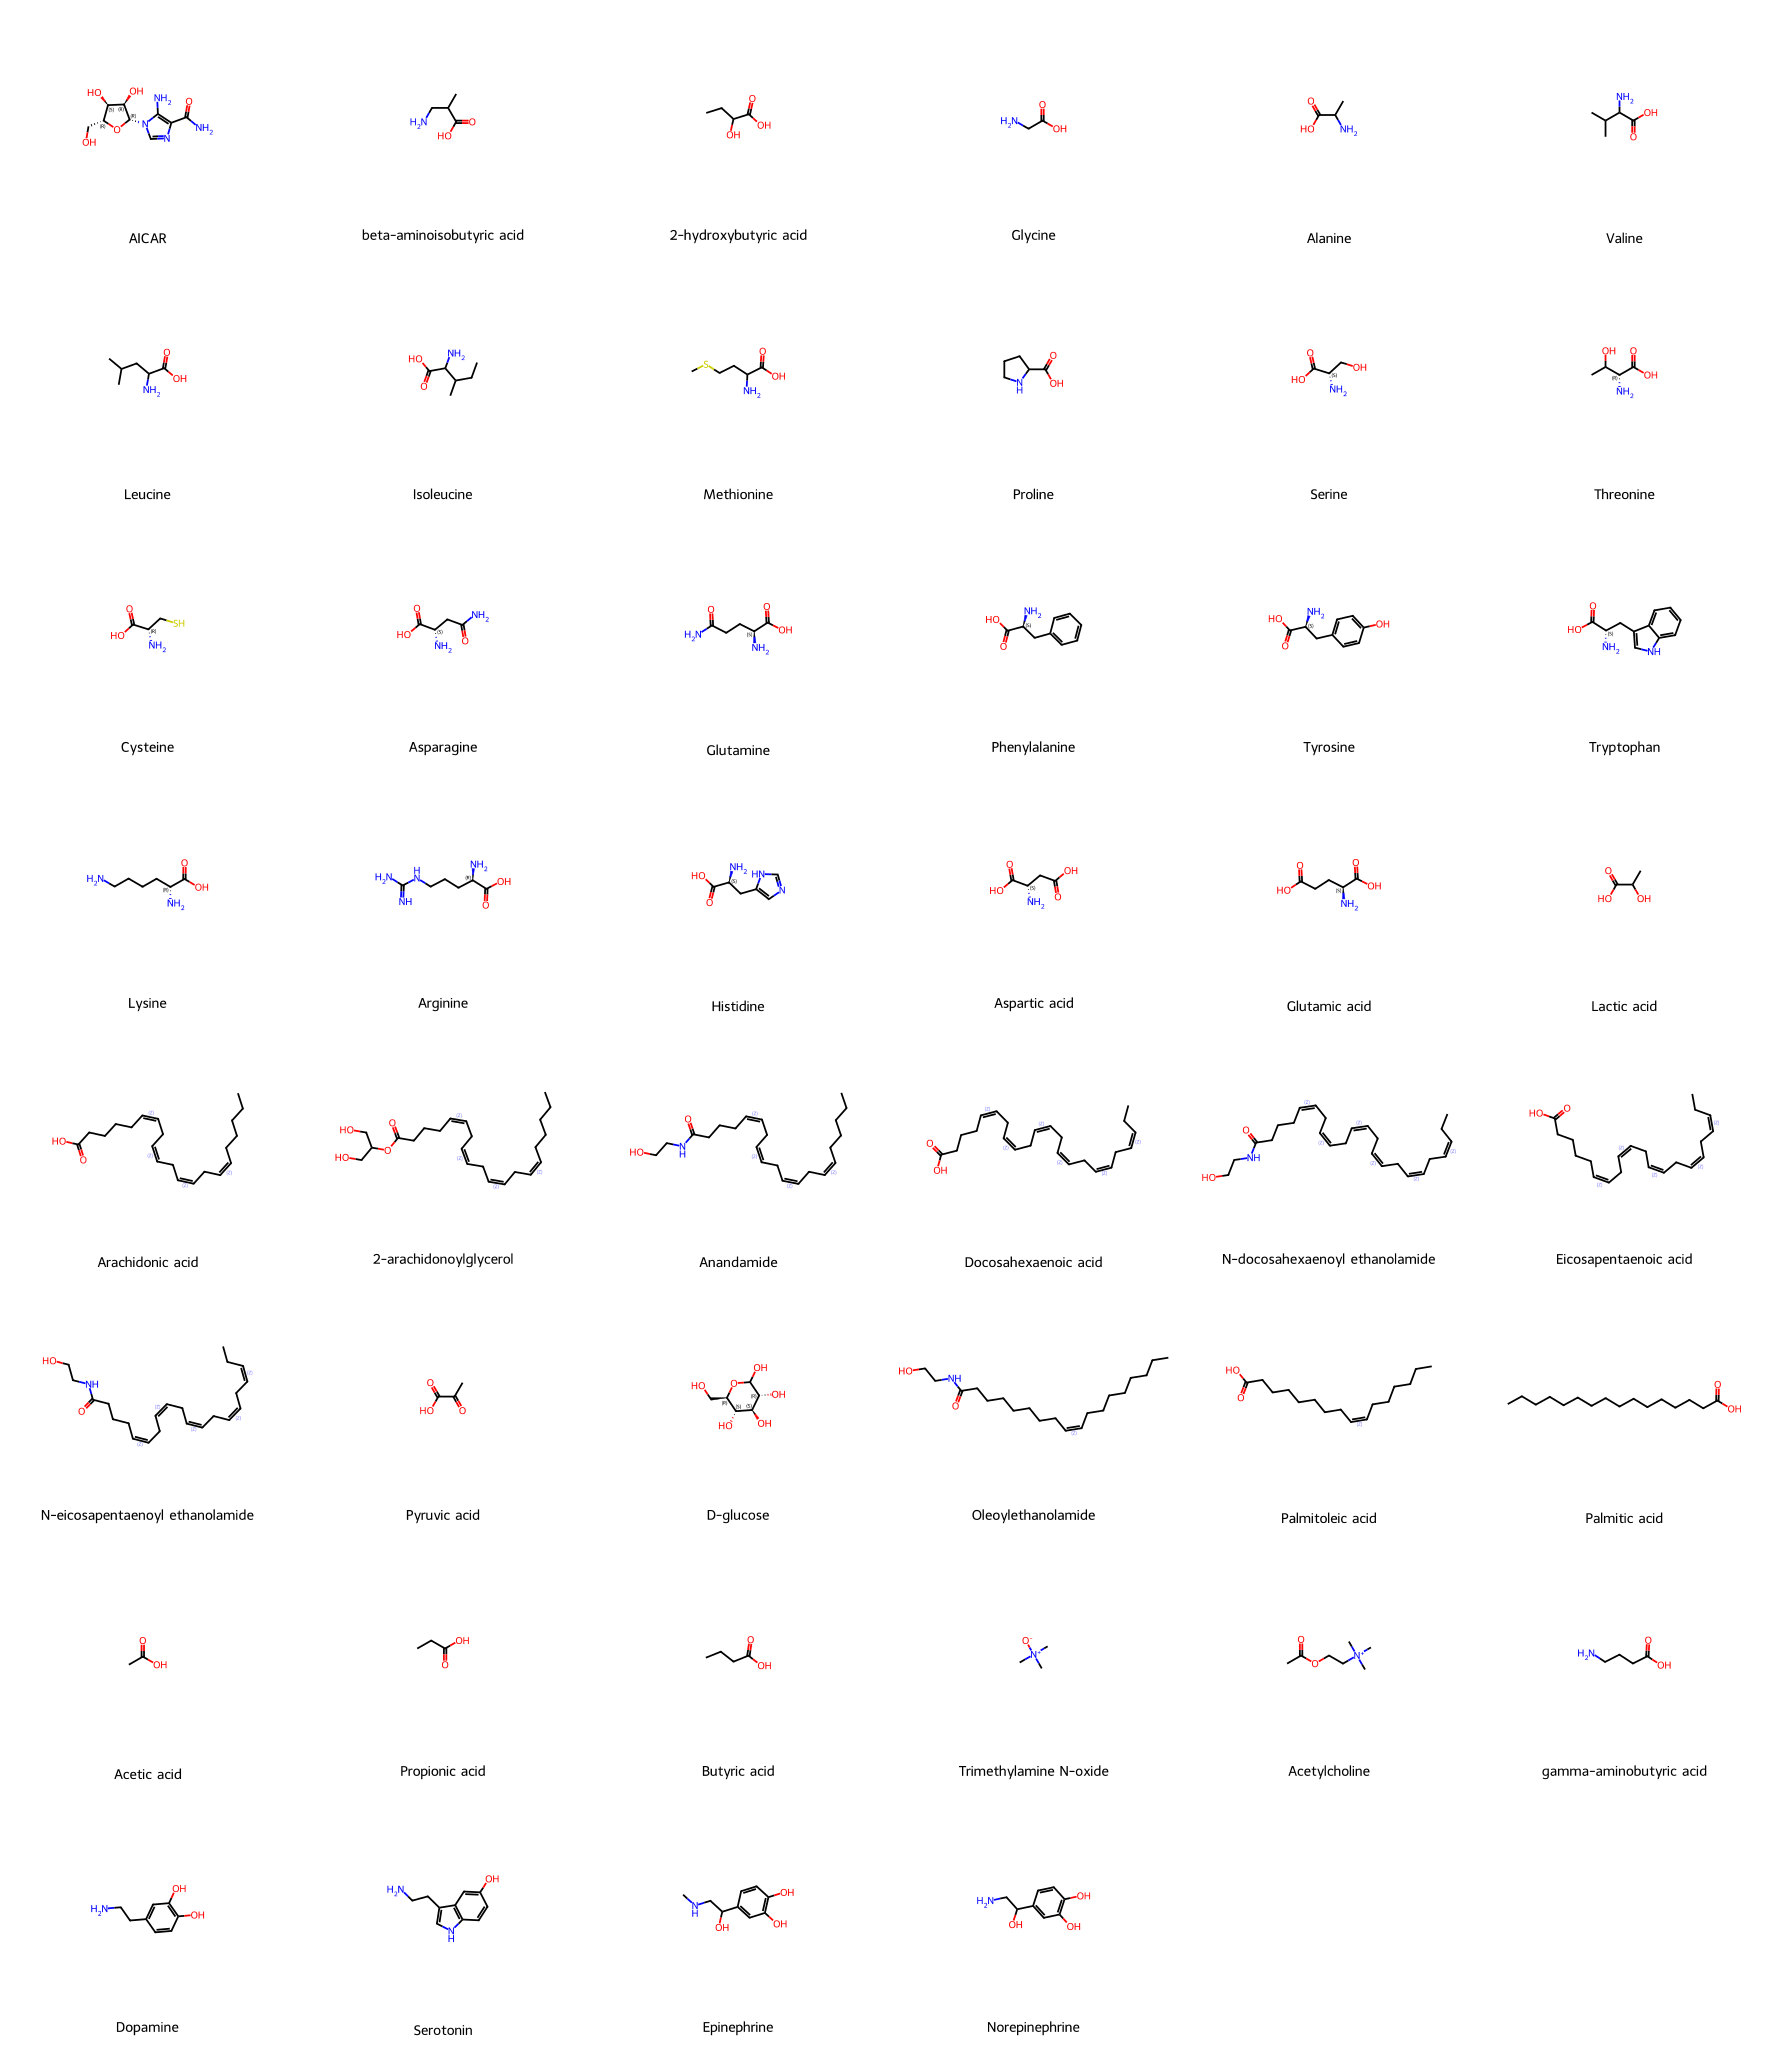

AttributeError: 'Image' object has no attribute 'save'

In [49]:
# Required dependencies: rdkit, IPython
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import display

# 1. Full dataset of 46 Exerkine Metabolites using Raw Strings (r"...")
exerkines_extended = [
    ("AICAR / acadesine vs ZMP", r"C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O)N)C(=O)N"),
    ("beta-aminoisobutyric acid (BAIBA)", r"CC(CN)C(=O)O"),
    ("2-hydroxybutyric acid / 2-hydroxybutyrate", r"CCC(C(=O)O)O"),
    ("Glycine", r"NCC(=O)O"),
    ("Alanine", r"CC(N)C(=O)O"),
    ("Valine", r"CC(C)C(N)C(=O)O"),
    ("Leucine", r"CC(C)CC(N)C(=O)O"),
    ("Isoleucine", r"CCC(C)C(N)C(=O)O"),
    ("Methionine", r"CSCCC(N)C(=O)O"),
    ("Proline", r"O=C(O)C1CCCN1"),
    ("Serine", r"N[C@@H](CO)C(=O)O"),
    ("Threonine", r"CC(O)[C@@H](N)C(=O)O"),
    ("Cysteine", r"N[C@@H](CS)C(=O)O"),
    ("Asparagine", r"N[C@@H](CC(N)=O)C(=O)O"),
    ("Glutamine", r"N[C@@H](CCC(N)=O)C(=O)O"),
    ("Phenylalanine", r"N[C@@H](Cc1ccccc1)C(=O)O"),
    ("Tyrosine", r"N[C@@H](Cc1ccc(O)cc1)C(=O)O"),
    ("Tryptophan", r"N[C@@H](Cc1c[nH]c2ccccc12)C(=O)O"),
    ("Lysine", r"NCCCC[C@@H](N)C(=O)O"),
    ("Arginine", r"N=C(N)NCCC[C@@H](N)C(=O)O"),
    ("Histidine", r"N[C@@H](Cc1cnc[nH]1)C(=O)O"),
    ("Aspartic acid / aspartate", r"N[C@@H](CC(=O)O)C(=O)O"),
    ("Glutamic acid / glutamate", r"N[C@@H](CCC(=O)O)C(=O)O"),
    ("Lactic acid / lactate", r"CC(O)C(=O)O"),
    ("Arachidonic acid (20:4 n-6)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("2-arachidonoylglycerol (2-AG)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)OC(CO)CO"),
    ("Anandamide (AEA)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Docosahexaenoic acid (DHA; 22:6 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)O"),
    ("N-docosahexaenoyl ethanolamide (DHEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Eicosapentaenoic acid (EPA; 20:5 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("N-eicosapentaenoyl ethanolamide (EPEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Pyruvic acid / pyruvate", r"CC(=O)C(=O)O"),
    ("D-glucose", r"C([C@@H]1[C@H]([C@@H]([C@H](C(O1)O)O)O)O)O"),
    ("Oleoylethanolamide (OEA)", r"CCCCCCCC/C=C\CCCCCCCC(=O)NCCO"),
    ("Palmitoleic acid (16:1 n-7)", r"CCCCCC/C=C\CCCCCCCC(=O)O"),
    ("Palmitic acid (16:0)", r"CCCCCCCCCCCCCCCC(=O)O"),
    ("Acetic acid / acetate", r"CC(=O)O"),
    ("Propionic acid / propionate", r"CCC(=O)O"),
    ("Butyric acid / butyrate", r"CCCC(=O)O"),
    ("Trimethylamine N-oxide (TMAO)", r"C[N+](C)(C)[O-]"),
    ("Acetylcholine", r"CC(=O)OCC[N+](C)(C)C"),
    ("gamma-aminobutyric acid (GABA)", r"NCCCC(=O)O"),
    ("Dopamine", r"NCCc1ccc(O)c(O)c1"),
    ("Serotonin (5-hydroxytryptamine)", r"NCCc1c[nH]c2ccc(O)cc12"),
    ("Epinephrine (adrenaline)", r"CNCC(O)c1cc(O)c(O)cc1"),
    ("Norepinephrine (noradrenaline)", r"NCC(O)c1cc(O)c(O)cc1")
]

# 2. Parse SMILES and Compute 2D Coordinates
mols = []
labels = []

for name, smiles in exerkines_extended:
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        Chem.rdDepictor.Compute2DCoords(mol)
        mols.append(mol)
        # Display clean name for figure legends
        clean_name = name.split(" / ")[0].split(" (")[0]
        labels.append(clean_name)

# 3. Configure Drawing Parameters for Wide-Aspect 6-Column Grid
draw_options = rdMolDraw2D.MolDrawOptions()
draw_options.addAtomIndices = False
draw_options.addStereoAnnotation = True
draw_options.bondLineWidth = 1.8
draw_options.legendFontSize = 14
draw_options.minFontSize = 10

# 4. Generate 6x8 Layout Grid (46 molecules across 8 rows)
svg_grid = Draw.MolsToGridImage(
    mols,
    molsPerRow=6,
    subImgSize=(300, 260),
    legends=labels,
    useSVG=True,
    drawOptions=draw_options
)

# 5. Display directly in Jupyter Notebook
display(svg_grid)

# 6. Save Renders to File Path
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
out_dir.mkdir(parents=True, exist_ok=True)

svg_string = svg_grid.data if hasattr(svg_grid, 'data') else str(svg_grid)
with open(out_dir / "exerkines_all_46_grid.svg", "w", encoding="utf-8") as f:
    f.write(svg_string)

png_img = Draw.MolsToGridImage(
    mols,
    molsPerRow=6,
    subImgSize=(450, 380),
    legends=labels,
    useSVG=False,
    drawOptions=draw_options
)
png_img.save(out_dir / "exerkines_all_46_grid.png")

print(f"Successfully generated structure plot for all {len(mols)} exerkines.")
print(f"Renders saved to:\n - {out_dir / 'exerkines_all_46_grid.svg'}\n - {out_dir / 'exerkines_all_46_grid.png'}")

In [48]:
# Required dependencies: pandas, numpy, scikit-learn, matplotlib, seaborn
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Try importing umap-learn with fallback to Scikit-learn PCA/t-SNE
try:
    import umap
    HAS_UMAP = True
except ImportError:
    from sklearn.decomposition import PCA
    from sklearn.manifold import TSNE
    HAS_UMAP = False
    print("Notice: 'umap-learn' not detected in environment. Falling back to PCA/t-SNE.")
    print("To install UMAP run: conda install -c conda-forge umap-learn")

# 1. Load Master Descriptor Table
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
master_file = out_dir / "exerkine_master_1d_2d_3d_descriptors.csv"

if not master_file.exists():
    # Fallback to 2D descriptors if master table hasn't been compiled yet
    master_file = out_dir / "exerkine_computational_descriptors.csv"

df_master = pd.read_csv(master_file)

# 2. Select Relevant Numerical Features for Dimensionality Reduction
candidate_features = [
    "mw_g_mol", "logp", "tpsa_ang2", "hbd", "hba", "rotatable_bonds", 
    "fraction_csp3", "formal_charge", "mean_radius_of_gyration", 
    "mean_asphericity", "mean_eccentricity", "mean_spherocity", 
    "mean_npmi1", "mean_npmi2"
]

feature_cols = [col for col in candidate_features if col in df_master.columns]

if len(feature_cols) < 3:
    raise ValueError(f"Insuffi# Required dependencies: rdkit, pandas, numpy
from pathlib import Path
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

# 1. Define Full Exerkine SMILES dataset using raw strings (r"...")
exerkines_extended = [
    ("AICAR / acadesine vs ZMP", r"C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O)N)C(=O)N"),
    ("beta-aminoisobutyric acid (BAIBA)", r"CC(CN)C(=O)O"),
    ("2-hydroxybutyric acid / 2-hydroxybutyrate", r"CCC(C(=O)O)O"),
    ("Glycine", r"NCC(=O)O"),
    ("Alanine", r"CC(N)C(=O)O"),
    ("Valine", r"CC(C)C(N)C(=O)O"),
    ("Leucine", r"CC(C)CC(N)C(=O)O"),
    ("Isoleucine", r"CCC(C)C(N)C(=O)O"),
    ("Methionine", r"CSCCC(N)C(=O)O"),
    ("Proline", r"O=C(O)C1CCCN1"),
    ("Serine", r"N[C@@H](CO)C(=O)O"),
    ("Threonine", r"CC(O)[C@@H](N)C(=O)O"),
    ("Cysteine", r"N[C@@H](CS)C(=O)O"),
    ("Asparagine", r"N[C@@H](CC(N)=O)C(=O)O"),
    ("Glutamine", r"N[C@@H](CCC(N)=O)C(=O)O"),
    ("Phenylalanine", r"N[C@@H](Cc1ccccc1)C(=O)O"),
    ("Tyrosine", r"N[C@@H](Cc1ccc(O)cc1)C(=O)O"),
    ("Tryptophan", r"N[C@@H](Cc1c[nH]c2ccccc12)C(=O)O"),
    ("Lysine", r"NCCCC[C@@H](N)C(=O)O"),
    ("Arginine", r"N=C(N)NCCC[C@@H](N)C(=O)O"),
    ("Histidine", r"N[C@@H](Cc1cnc[nH]1)C(=O)O"),
    ("Aspartic acid / aspartate", r"N[C@@H](CC(=O)O)C(=O)O"),
    ("Glutamic acid / glutamate", r"N[C@@H](CCC(=O)O)C(=O)O"),
    ("Lactic acid / lactate", r"CC(O)C(=O)O"),
    ("Arachidonic acid (20:4 n-6)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("2-arachidonoylglycerol (2-AG)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)OC(CO)CO"),
    ("Anandamide (AEA)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Docosahexaenoic acid (DHA; 22:6 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)O"),
    ("N-docosahexaenoyl ethanolamide (DHEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Eicosapentaenoic acid (EPA; 20:5 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("N-eicosapentaenoyl ethanolamide (EPEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Pyruvic acid / pyruvate", r"CC(=O)C(=O)O"),
    ("D-glucose", r"C([C@@H]1[C@H]([C@@H]([C@H](C(O1)O)O)O)O)O"),
    ("Oleoylethanolamide (OEA)", r"CCCCCCCC/C=C\CCCCCCCC(=O)NCCO"),
    ("Palmitoleic acid (16:1 n-7)", r"CCCCCC/C=C\CCCCCCCC(=O)O"),
    ("Palmitic acid (16:0)", r"CCCCCCCCCCCCCCCC(=O)O"),
    ("Acetic acid / acetate", r"CC(=O)O"),
    ("Propionic acid / propionate", r"CCC(=O)O"),
    ("Butyric acid / butyrate", r"CCCC(=O)O"),
    ("Trimethylamine N-oxide (TMAO)", r"C[N+](C)(C)[O-]"),
    ("Acetylcholine", r"CC(=O)OCC[N+](C)(C)C"),
    ("gamma-aminobutyric acid (GABA)", r"NCCCC(=O)O"),
    ("Dopamine", r"NCCc1ccc(O)c(O)c1"),
    ("Serotonin (5-hydroxytryptamine)", r"NCCc1c[nH]c2ccc(O)cc12"),
    ("Epinephrine (adrenaline)", r"CNCC(O)c1cc(O)c(O)cc1"),
    ("Norepinephrine (noradrenaline)", r"NCC(O)c1cc(O)c(O)cc1")
]

# 2. Compute Chemoinformatic Descriptors
records = []

for name, smiles in exerkines_extended:
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print(f"Failed to parse SMILES for {name}")
        continue
        
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    tpsa = Descriptors.TPSA(mol)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)
    rot_bonds = Lipinski.NumRotatableBonds(mol)
    f_csp3 = rdMolDescriptors.CalcFractionCSP3(mol)
    formal_charge = Chem.GetFormalCharge(mol)
    
    # Calculate Lipinski Rule of 5 violations
    violations = sum([
        mw > 500,
        logp > 5,
        hbd > 5,
        hba > 10
    ])
    
    records.append({
        "metabolite": name,
        "SMILES": smiles,
        "mw_g_mol": round(mw, 2),
        "logp": round(logp, 2),
        "tpsa_ang2": round(tpsa, 2),
        "hbd": hbd,
        "hba": hba,
        "rotatable_bonds": rot_bonds,
        "fraction_csp3": round(f_csp3, 2),
        "formal_charge": formal_charge,
        "lipinski_violations": violations
    })

df_desc = pd.DataFrame(records)

# 3. Merge Ensemble Energetics from QC table (if available)
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
out_dir.mkdir(parents=True, exist_ok=True)
qc_file = out_dir / "conformer_energies_qc.csv"

if qc_file.exists():
    df_qc = pd.read_csv(qc_file)
    energy_col = 'solvated_energy_kj_mol' if 'solvated_energy_kj_mol' in df_qc.columns else 'openmm_energy_kj_mol'
    
    if energy_col in df_qc.columns:
        stats = df_qc.groupby('metabolite')[energy_col].agg(
            min_energy_kj_mol='min',
            max_energy_kj_mol='max',
            mean_energy_kj_mol='mean'
        ).reset_index()
        
        stats['delta_E_kj_mol'] = stats['max_energy_kj_mol'] - stats['min_energy_kj_mol']
        df_desc = pd.merge(df_desc, stats, on='metabolite', how='left')

# 4. Save to CSV
output_path = out_dir / "exerkine_computational_descriptors.csv"
df_desc.to_csv(output_path, index=False)
print(f"Successfully processed {len(df_desc)} exerkines.")
print(f"Saved computational descriptors table to: {output_path}")

# Display the first 15 rows formatted in the notebook
df_desc.head(15)cient numerical features found in {master_file.name} for UMAP projection.")

# 3. Preprocess Features: Impute Missing Values & Standard Scale
X_raw = df_master[feature_cols].values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# 4. Compute Manifold Projection
if HAS_UMAP:
    reducer = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        metric="euclidean",
        random_state=20261019
    )
    embedding = reducer.fit_transform(X_scaled)
    dim_labels = ("UMAP 1", "UMAP 2")
    title_suffix = "UMAP Projection"
else:
    reducer = PCA(n_components=2, random_state=20261019)
    embedding = reducer.fit_transform(X_scaled)
    dim_labels = (f"PC 1 ({reducer.explained_variance_ratio_[0]*100:.1f}%)", 
                  f"PC 2 ({reducer.explained_variance_ratio_[1]*100:.1f}%)")
    title_suffix = "PCA Projection (Fallback)"

df_master["Dim1"] = embedding[:, 0]
df_master["Dim2"] = embedding[:, 1]

# 5. Publication-Quality Plotting
sns.set_theme(style="whitegrid", font="sans-serif")
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=300)

# Determine continuous hue mapping based on available features (prefer LogP or Mw)
hue_col = "logp" if "logp" in df_master.columns else "mw_g_mol"
scatter = ax.scatter(
    df_master["Dim1"],
    df_master["Dim2"],
    c=df_master[hue_col],
    cmap="plasma",
    s=120,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    zorder=3
)

# Add Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label(f"Wildman-Crippen {hue_col.upper()}", fontsize=12, labelpad=10)

# Annotate Exerkine Metabolite Names
for _, row in df_master.iterrows():
    name = str(row["metabolite"])
    # Clean up name label for display
    clean_label = name.split(". ")[-1] if ". " in name else name
    ax.annotate(
        clean_label,
        (row["Dim1"], row["Dim2"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
        alpha=0.85,
        weight="semibold"
    )

ax.set_xlabel(dim_labels[0], fontsize=13, fontweight="bold")
ax.set_ylabel(dim_labels[1], fontsize=13, fontweight="bold")
ax.set_title(f"Exerkine Chemical & Conformational Space ({title_suffix})", fontsize=15, fontweight="bold", pad=12)

plt.tight_layout()

# Save High-Resolution Renders
out_svg = out_dir / "exerkine_umap_chemical_space.svg"
out_png = out_dir / "exerkine_umap_chemical_space.png"
fig.savefig(out_svg, format="svg", bbox_inches="tight")
fig.savefig(out_png, format="png", dpi=300, bbox_inches="tight")

plt.show()# Required dependencies: rdkit, pandas, numpy
from pathlib import Path
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

# 1. Define Full Exerkine SMILES dataset using raw strings (r"...")
exerkines_extended = [
    ("AICAR / acadesine vs ZMP", r"C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O)N)C(=O)N"),
    ("beta-aminoisobutyric acid (BAIBA)", r"CC(CN)C(=O)O"),
    ("2-hydroxybutyric acid / 2-hydroxybutyrate", r"CCC(C(=O)O)O"),
    ("Glycine", r"NCC(=O)O"),
    ("Alanine", r"CC(N)C(=O)O"),
    ("Valine", r"CC(C)C(N)C(=O)O"),
    ("Leucine", r"CC(C)CC(N)C(=O)O"),
    ("Isoleucine", r"CCC(C)C(N)C(=O)O"),
    ("Methionine", r"CSCCC(N)C(=O)O"),
    ("Proline", r"O=C(O)C1CCCN1"),
    ("Serine", r"N[C@@H](CO)C(=O)O"),
    ("Threonine", r"CC(O)[C@@H](N)C(=O)O"),
    ("Cysteine", r"N[C@@H](CS)C(=O)O"),
    ("Asparagine", r"N[C@@H](CC(N)=O)C(=O)O"),
    ("Glutamine", r"N[C@@H](CCC(N)=O)C(=O)O"),
    ("Phenylalanine", r"N[C@@H](Cc1ccccc1)C(=O)O"),
    ("Tyrosine", r"N[C@@H](Cc1ccc(O)cc1)C(=O)O"),
    ("Tryptophan", r"N[C@@H](Cc1c[nH]c2ccccc12)C(=O)O"),
    ("Lysine", r"NCCCC[C@@H](N)C(=O)O"),
    ("Arginine", r"N=C(N)NCCC[C@@H](N)C(=O)O"),
    ("Histidine", r"N[C@@H](Cc1cnc[nH]1)C(=O)O"),
    ("Aspartic acid / aspartate", r"N[C@@H](CC(=O)O)C(=O)O"),
    ("Glutamic acid / glutamate", r"N[C@@H](CCC(=O)O)C(=O)O"),
    ("Lactic acid / lactate", r"CC(O)C(=O)O"),
    ("Arachidonic acid (20:4 n-6)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("2-arachidonoylglycerol (2-AG)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)OC(CO)CO"),
    ("Anandamide (AEA)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Docosahexaenoic acid (DHA; 22:6 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)O"),
    ("N-docosahexaenoyl ethanolamide (DHEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Eicosapentaenoic acid (EPA; 20:5 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("N-eicosapentaenoyl ethanolamide (EPEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Pyruvic acid / pyruvate", r"CC(=O)C(=O)O"),
    ("D-glucose", r"C([C@@H]1[C@H]([C@@H]([C@H](C(O1)O)O)O)O)O"),
    ("Oleoylethanolamide (OEA)", r"CCCCCCCC/C=C\CCCCCCCC(=O)NCCO"),
    ("Palmitoleic acid (16:1 n-7)", r"CCCCCC/C=C\CCCCCCCC(=O)O"),
    ("Palmitic acid (16:0)", r"CCCCCCCCCCCCCCCC(=O)O"),
    ("Acetic acid / acetate", r"CC(=O)O"),
    ("Propionic acid / propionate", r"CCC(=O)O"),
    ("Butyric acid / butyrate", r"CCCC(=O)O"),
    ("Trimethylamine N-oxide (TMAO)", r"C[N+](C)(C)[O-]"),
    ("Acetylcholine", r"CC(=O)OCC[N+](C)(C)C"),
    ("gamma-aminobutyric acid (GABA)", r"NCCCC(=O)O"),
    ("Dopamine", r"NCCc1ccc(O)c(O)c1"),
    ("Serotonin (5-hydroxytryptamine)", r"NCCc1c[nH]c2ccc(O)cc12"),
    ("Epinephrine (adrenaline)", r"CNCC(O)c1cc(O)c(O)cc1"),
    ("Norepinephrine (noradrenaline)", r"NCC(O)c1cc(O)c(O)cc1")
]

# 2. Compute Chemoinformatic Descriptors
records = []

for name, smiles in exerkines_extended:
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print(f"Failed to parse SMILES for {name}")
        continue
        
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    tpsa = Descriptors.TPSA(mol)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)
    rot_bonds = Lipinski.NumRotatableBonds(mol)
    f_csp3 = rdMolDescriptors.CalcFractionCSP3(mol)
    formal_charge = Chem.GetFormalCharge(mol)
    
    # Calculate Lipinski Rule of 5 violations
    violations = sum([
        mw > 500,
        logp > 5,
        hbd > 5,
        hba > 10
    ])
    
    records.append({
        "metabolite": name,
        "SMILES": smiles,
        "mw_g_mol": round(mw, 2),
        "logp": round(logp, 2),
        "tpsa_ang2": round(tpsa, 2),
        "hbd": hbd,
        "hba": hba,
        "rotatable_bonds": rot_bonds,
        "fraction_csp3": round(f_csp3, 2),
        "formal_charge": formal_charge,
        "lipinski_violations": violations
    })

df_desc = pd.DataFrame(records)

# 3. Merge Ensemble Energetics from QC table (if available)
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
out_dir.mkdir(parents=True, exist_ok=True)
qc_file = out_dir / "conformer_energies_qc.csv"

if qc_file.exists():
    df_qc = pd.read_csv(qc_file)
    energy_col = 'solvated_energy_kj_mol' if 'solvated_energy_kj_mol' in df_qc.columns else 'openmm_energy_kj_mol'
    
    if energy_col in df_qc.columns:
        stats = df_qc.groupby('metabolite')[energy_col].agg(
            min_energy_kj_mol='min',
            max_energy_kj_mol='max',
            mean_energy_kj_mol='mean'
        ).reset_index()
        
        stats['delta_E_kj_mol'] = stats['max_energy_kj_mol'] - stats['min_energy_kj_mol']
        df_desc = pd.merge(df_desc, stats, on='metabolite', how='left')

# 4. Save to CSV
output_path = out_dir / "exerkine_computational_descriptors.csv"
df_desc.to_csv(output_path, index=False)
print(f"Successfully processed {len(df_desc)} exerkines.")
print(f"Saved computational descriptors table to: {output_path}")

# Display the first 15 rows formatted in the notebook
df_desc.head(15)

print(f"Clustering complete across {len(df_master)} exerkines and {len(feature_cols)} features.")
print(f"Renders saved to:\n - {out_svg}\n - {out_png}")

SyntaxError: unterminated f-string literal (detected at line 42) (4126203192.py, line 42)

In [43]:
# Required dependencies: rdkit, pandas, numpy
from pathlib import Path
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

# 1. Define Full Exerkine SMILES dataset using raw strings (r"...")
exerkines_extended = [
    ("AICAR / acadesine vs ZMP", r"C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O)N)C(=O)N"),
    ("beta-aminoisobutyric acid (BAIBA)", r"CC(CN)C(=O)O"),
    ("2-hydroxybutyric acid / 2-hydroxybutyrate", r"CCC(C(=O)O)O"),
    ("Glycine", r"NCC(=O)O"),
    ("Alanine", r"CC(N)C(=O)O"),
    ("Valine", r"CC(C)C(N)C(=O)O"),
    ("Leucine", r"CC(C)CC(N)C(=O)O"),
    ("Isoleucine", r"CCC(C)C(N)C(=O)O"),
    ("Methionine", r"CSCCC(N)C(=O)O"),
    ("Proline", r"O=C(O)C1CCCN1"),
    ("Serine", r"N[C@@H](CO)C(=O)O"),
    ("Threonine", r"CC(O)[C@@H](N)C(=O)O"),
    ("Cysteine", r"N[C@@H](CS)C(=O)O"),
    ("Asparagine", r"N[C@@H](CC(N)=O)C(=O)O"),
    ("Glutamine", r"N[C@@H](CCC(N)=O)C(=O)O"),
    ("Phenylalanine", r"N[C@@H](Cc1ccccc1)C(=O)O"),
    ("Tyrosine", r"N[C@@H](Cc1ccc(O)cc1)C(=O)O"),
    ("Tryptophan", r"N[C@@H](Cc1c[nH]c2ccccc12)C(=O)O"),
    ("Lysine", r"NCCCC[C@@H](N)C(=O)O"),
    ("Arginine", r"N=C(N)NCCC[C@@H](N)C(=O)O"),
    ("Histidine", r"N[C@@H](Cc1cnc[nH]1)C(=O)O"),
    ("Aspartic acid / aspartate", r"N[C@@H](CC(=O)O)C(=O)O"),
    ("Glutamic acid / glutamate", r"N[C@@H](CCC(=O)O)C(=O)O"),
    ("Lactic acid / lactate", r"CC(O)C(=O)O"),
    ("Arachidonic acid (20:4 n-6)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("2-arachidonoylglycerol (2-AG)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)OC(CO)CO"),
    ("Anandamide (AEA)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Docosahexaenoic acid (DHA; 22:6 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)O"),
    ("N-docosahexaenoyl ethanolamide (DHEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Eicosapentaenoic acid (EPA; 20:5 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("N-eicosapentaenoyl ethanolamide (EPEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Pyruvic acid / pyruvate", r"CC(=O)C(=O)O"),
    ("D-glucose", r"C([C@@H]1[C@H]([C@@H]([C@H](C(O1)O)O)O)O)O"),
    ("Oleoylethanolamide (OEA)", r"CCCCCCCC/C=C\CCCCCCCC(=O)NCCO"),
    ("Palmitoleic acid (16:1 n-7)", r"CCCCCC/C=C\CCCCCCCC(=O)O"),
    ("Palmitic acid (16:0)", r"CCCCCCCCCCCCCCCC(=O)O"),
    ("Acetic acid / acetate", r"CC(=O)O"),
    ("Propionic acid / propionate", r"CCC(=O)O"),
    ("Butyric acid / butyrate", r"CCCC(=O)O"),
    ("Trimethylamine N-oxide (TMAO)", r"C[N+](C)(C)[O-]"),
    ("Acetylcholine", r"CC(=O)OCC[N+](C)(C)C"),
    ("gamma-aminobutyric acid (GABA)", r"NCCCC(=O)O"),
    ("Dopamine", r"NCCc1ccc(O)c(O)c1"),
    ("Serotonin (5-hydroxytryptamine)", r"NCCc1c[nH]c2ccc(O)cc12"),
    ("Epinephrine (adrenaline)", r"CNCC(O)c1cc(O)c(O)cc1"),
    ("Norepinephrine (noradrenaline)", r"NCC(O)c1cc(O)c(O)cc1")
]

# 2. Compute Chemoinformatic Descriptors
records = []

for name, smiles in exerkines_extended:
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print(f"Failed to parse SMILES for {name}")
        continue
        
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    tpsa = Descriptors.TPSA(mol)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)
    rot_bonds = Lipinski.NumRotatableBonds(mol)
    f_csp3 = rdMolDescriptors.CalcFractionCSP3(mol)
    formal_charge = Chem.GetFormalCharge(mol)
    
    # Calculate Lipinski Rule of 5 violations
    violations = sum([
        mw > 500,
        logp > 5,
        hbd > 5,
        hba > 10
    ])
    
    records.append({
        "metabolite": name,
        "SMILES": smiles,
        "mw_g_mol": round(mw, 2),
        "logp": round(logp, 2),
        "tpsa_ang2": round(tpsa, 2),
        "hbd": hbd,
        "hba": hba,
        "rotatable_bonds": rot_bonds,
        "fraction_csp3": round(f_csp3, 2),
        "formal_charge": formal_charge,
        "lipinski_violations": violations
    })

df_desc = pd.DataFrame(records)

# 3. Merge Ensemble Energetics from QC table (if available)
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
out_dir.mkdir(parents=True, exist_ok=True)
qc_file = out_dir / "conformer_energies_qc.csv"

if qc_file.exists():
    df_qc = pd.read_csv(qc_file)
    energy_col = 'solvated_energy_kj_mol' if 'solvated_energy_kj_mol' in df_qc.columns else 'openmm_energy_kj_mol'
    
    if energy_col in df_qc.columns:
        stats = df_qc.groupby('metabolite')[energy_col].agg(
            min_energy_kj_mol='min',
            max_energy_kj_mol='max',
            mean_energy_kj_mol='mean'
        ).reset_index()
        
        stats['delta_E_kj_mol'] = stats['max_energy_kj_mol'] - stats['min_energy_kj_mol']
        df_desc = pd.merge(df_desc, stats, on='metabolite', how='left')

# 4. Save to CSV
output_path = out_dir / "exerkine_computational_descriptors.csv"
df_desc.to_csv(output_path, index=False)
print(f"Successfully processed {len(df_desc)} exerkines.")
print(f"Saved computational descriptors table to: {output_path}")

# Display the first 15 rows formatted in the notebook
df_desc.head(15)

Successfully processed 46 exerkines.
Saved computational descriptors table to: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs/exerkine_computational_descriptors.csv


,metabolite,SMILES,mw_g_mol,logp,tpsa_ang2,hbd,hba,rotatable_bonds,fraction_csp3,formal_charge,lipinski_violations,min_energy_kj_mol,max_energy_kj_mol,mean_energy_kj_mol,delta_E_kj_mol
0,AICAR / acadesine vs ZMP,C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O...,258.23,-2.82,156.85,5,7,3,0.56,0,0,NaN,NaN,NaN,NaN
1,beta-aminoisobutyric acid (BAIBA),CC(CN)C(=O)O,103.12,-0.33,63.32,2,2,2,0.75,0,0,NaN,NaN,NaN,NaN
2,2-hydroxybutyric acid / 2-hydroxybutyrate,CCC(C(=O)O)O,104.10,-0.16,57.53,2,2,2,0.75,0,0,NaN,NaN,NaN,NaN
3,Glycine,NCC(=O)O,75.07,-0.97,63.32,2,2,1,0.50,0,0,NaN,NaN,NaN,NaN
4,Alanine,CC(N)C(=O)O,89.09,-0.58,63.32,2,2,1,0.67,0,0,NaN,NaN,NaN,NaN
5,Valine,CC(C)C(N)C(=O)O,117.15,0.05,63.32,2,2,2,0.80,0,0,NaN,NaN,NaN,NaN
6,Leucine,CC(C)CC(N)C(=O)O,131.18,0.44,63.32,2,2,3,0.83,0,0,NaN,NaN,NaN,NaN
7,Isoleucine,CCC(C)C(N)C(=O)O,131.18,0.44,63.32,2,2,3,0.83,0,0,NaN,NaN,NaN,NaN
8,Methionine,CSCCC(N)C(=O)O,149.22,0.15,63.32,2,3,4,0.80,0,0,NaN,NaN,NaN,NaN
9,Proline,O=C(O)C1CCCN1,115.13,-0.18,49.33,2,2,1,0.80,0,0,NaN,NaN,NaN,NaN


In [36]:
# Required dependencies: pandas, numpy, scikit-learn, matplotlib, seaborn
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Try importing umap-learn with fallback to Scikit-learn PCA
try:
    import umap
    HAS_UMAP = True
except ImportError:
    from sklearn.decomposition import PCA
    HAS_UMAP = False
    print("Notice: 'umap-learn' not detected in environment. Falling back to PCA.")
    print("To install UMAP run: conda install -c conda-forge umap-learn")

# 1. Load Master Descriptor Table
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
master_file = out_dir / "exerkine_master_1d_2d_3d_descriptors.csv"

if not master_file.exists():
    master_file = out_dir / "exerkine_computational_descriptors.csv"

df_master = pd.read_csv(master_file)

# 2. Select Relevant Numerical Features
candidate_features = [
    "mw_g_mol", "logp", "tpsa_ang2", "hbd", "hba", "rotatable_bonds", 
    "fraction_csp3", "formal_charge", "mean_radius_of_gyration", 
    "mean_asphericity", "mean_eccentricity", "mean_spherocity", 
    "mean_npmi1", "mean_npmi2"
]

feature_cols = [col for col in candidate_features if col in df_master.columns]

if len(feature_cols) < 3:
    raise ValueError(f"Insufficient numerical features found in {master_file.name} for projection.")

# 3. Native Pandas Imputation & Standardization (Bypasses sklearn.impute Cython import)
df_features = df_master[feature_cols].copy()
df_imputed = df_features.fillna(df_features.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_imputed)

# 4. Compute Manifold Projection
if HAS_UMAP:
    reducer = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        metric="euclidean",
        random_state=20261019
    )
    embedding = reducer.fit_transform(X_scaled)
    dim_labels = ("UMAP 1", "UMAP 2")
    title_suffix = "UMAP Projection"
else:
    reducer = PCA(n_components=2, random_state=20261019)
    embedding = reducer.fit_transform(X_scaled)
    dim_labels = (f"PC 1 ({reducer.explained_variance_ratio_[0]*100:.1f}%)", 
                  f"PC 2 ({reducer.explained_variance_ratio_[1]*100:.1f}%)")
    title_suffix = "PCA Projection (Fallback)"

df_master["Dim1"] = embedding[:, 0]
df_master["Dim2"] = embedding[:, 1]

# 5. Publication-Quality Plotting
sns.set_theme(style="whitegrid", font="sans-serif")
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=300)

hue_col = "logp" if "logp" in df_master.columns else "mw_g_mol"
scatter = ax.scatter(
    df_master["Dim1"],
    df_master["Dim2"],
    c=df_master[hue_col],
    cmap="plasma",
    s=120,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    zorder=3
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label(f"Wildman-Crippen {hue_col.upper()}", fontsize=12, labelpad=10)

for _, row in df_master.iterrows():
    name = str(row["metabolite"])
    clean_label = name.split(". ")[-1] if ". " in name else name
    ax.annotate(
        clean_label,
        (row["Dim1"], row["Dim2"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
        alpha=0.85,
        weight="semibold"
    )

ax.set_xlabel(dim_labels[0], fontsize=13, fontweight="bold")
ax.set_ylabel(dim_labels[1], fontsize=13, fontweight="bold")
ax.set_title(f"Exerkine Chemical & Conformational Space ({title_suffix})", fontsize=15, fontweight="bold", pad=12)

plt.tight_layout()

# Save High-Resolution Renders
out_svg = out_dir / "exerkine_umap_chemical_space.svg"
out_png = out_dir / "exerkine_umap_chemical_space.png"
fig.savefig(out_svg, format="svg", bbox_inches="tight")
fig.savefig(out_png, format="png", dpi=300, bbox_inches="tight")

plt.show()

print(f"Projection complete across {len(df_master)} exerkines and {len(feature_cols)} features.")
print(f"Renders saved to:\n - {out_svg}\n - {out_png}")

ImportError: sklearn._cyutility does not export expected C function __Pyx_CyFunction_New

findfont: Failed to find font weight semibold for Arial, now using 700.


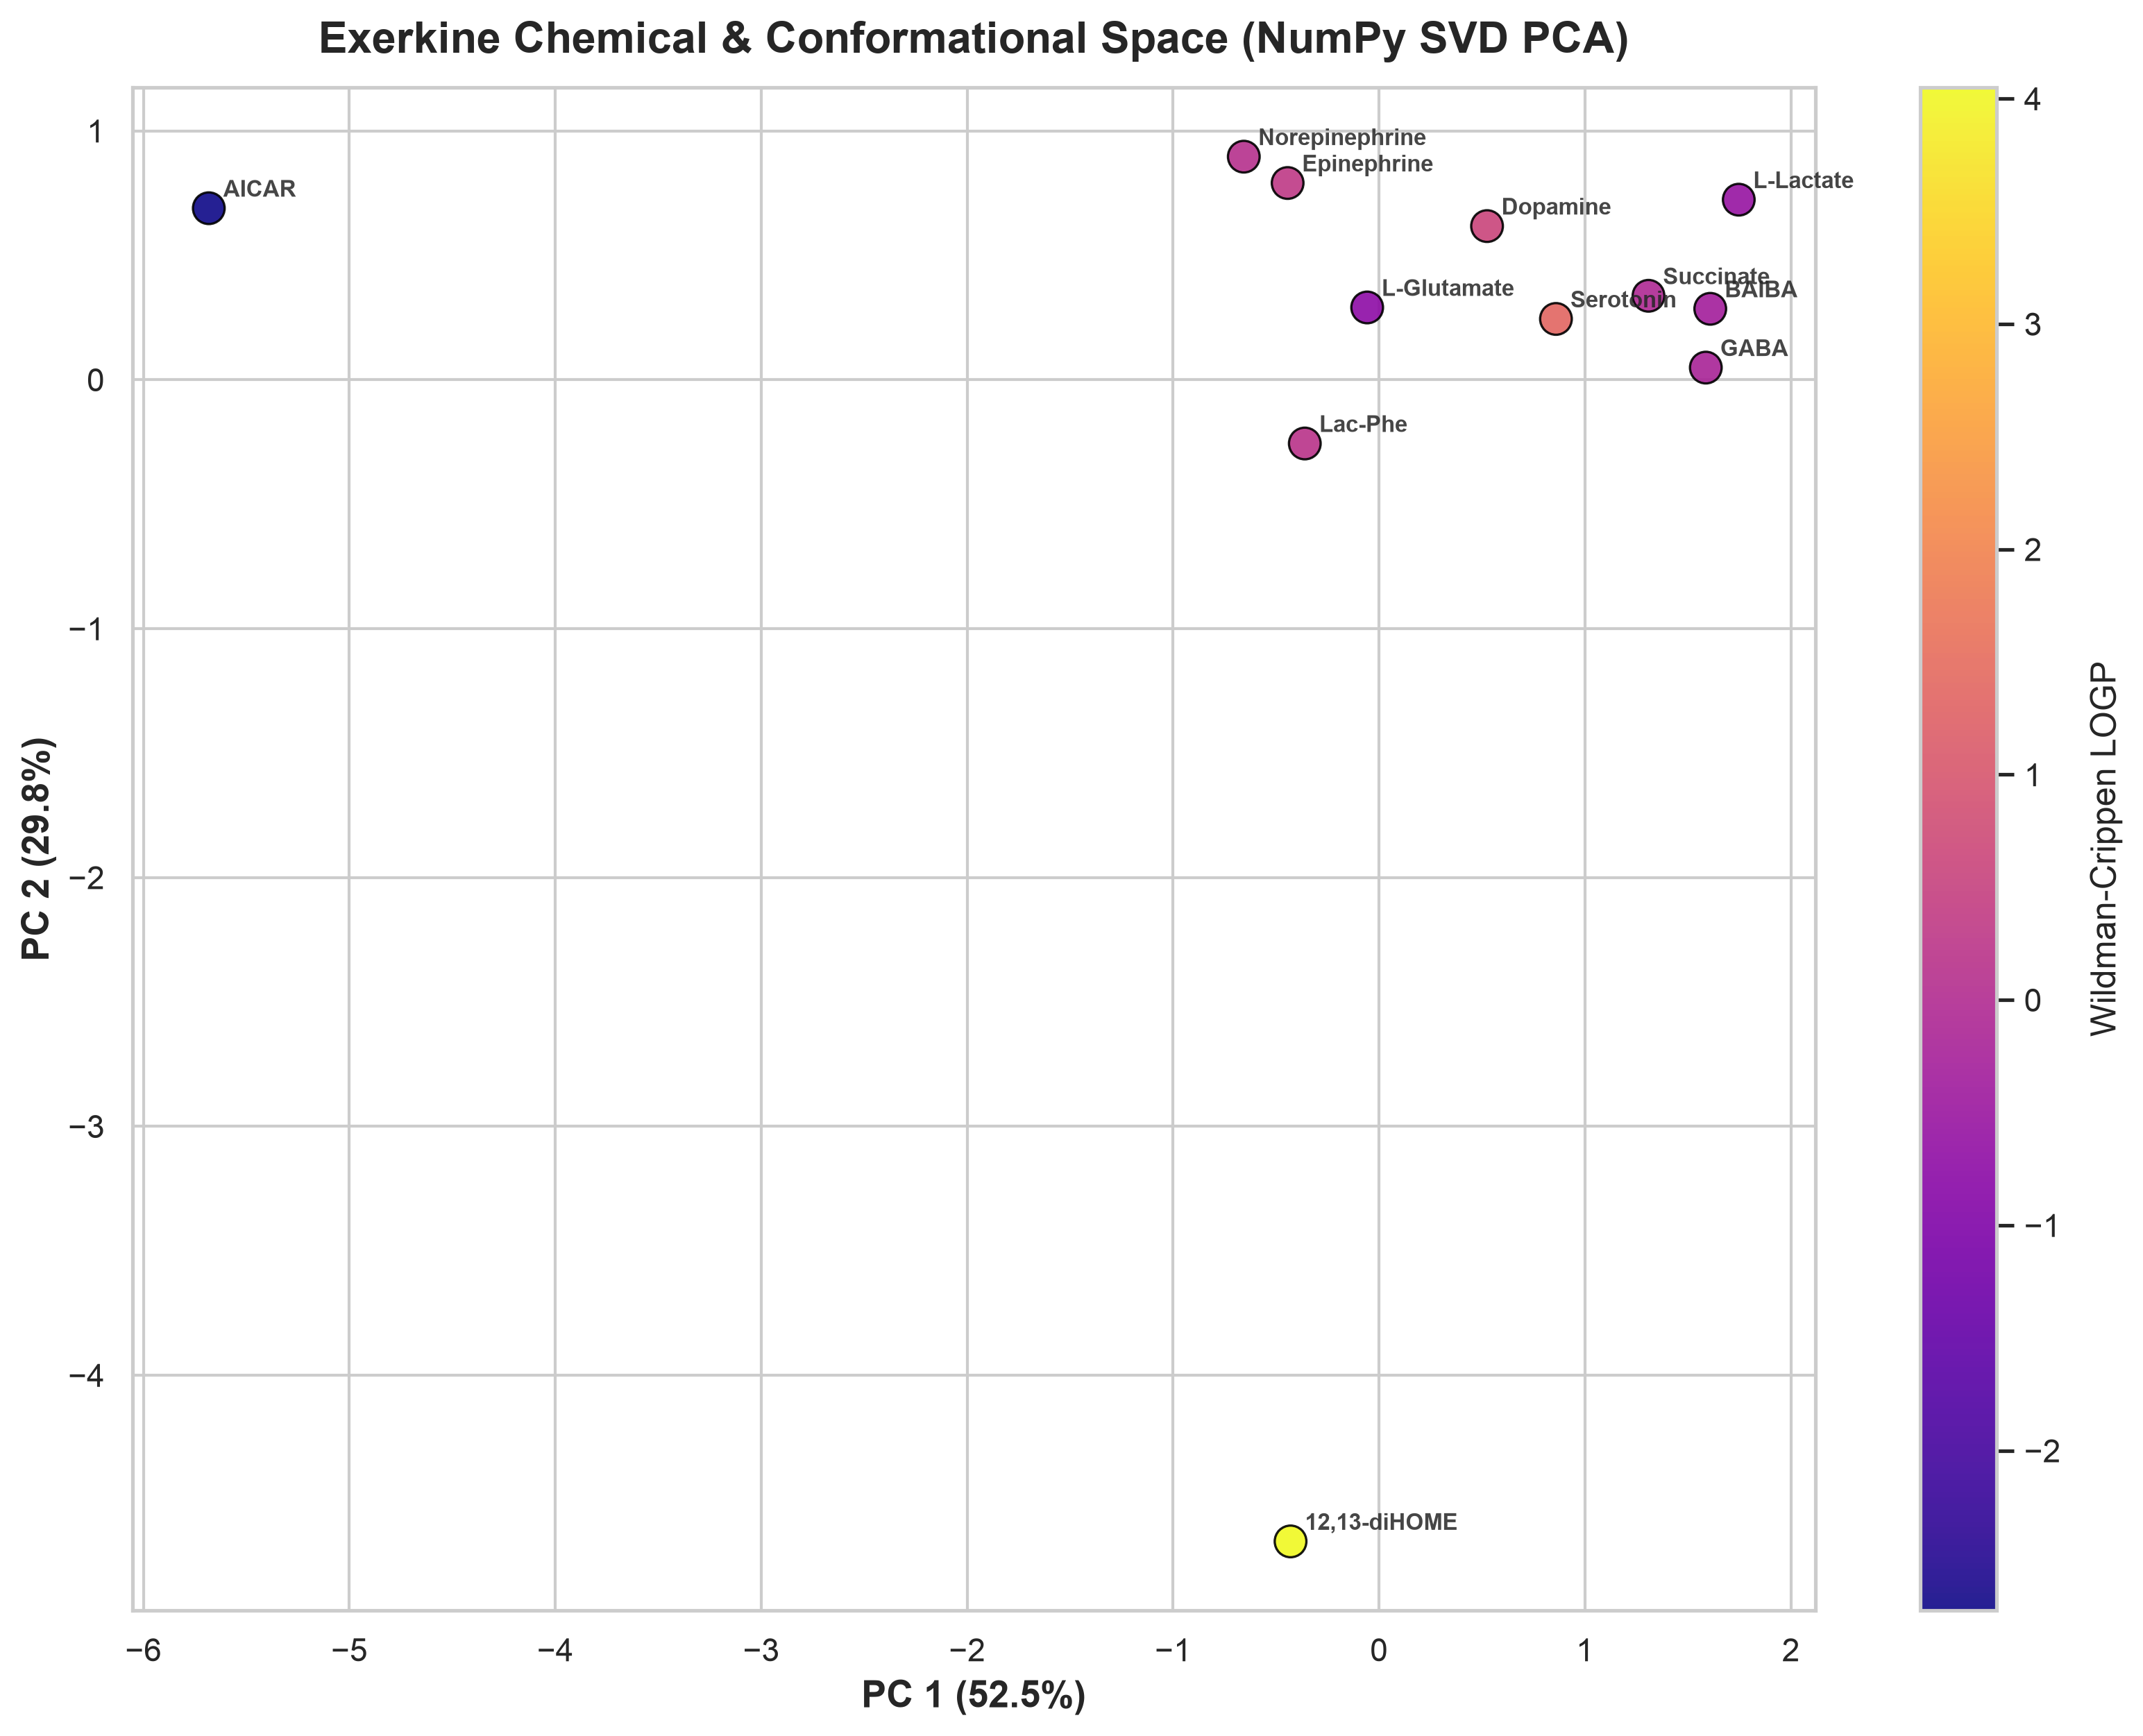

NumPy PCA complete across 12 exerkines and 8 features.
Renders saved to:
 - /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs/exerkine_pca_chemical_space.svg
 - /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs/exerkine_pca_chemical_space.png


In [24]:
# Required dependencies: pandas, numpy, matplotlib, seaborn (No sklearn/umap imports)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Master Descriptor Table
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
master_file = out_dir / "exerkine_master_1d_2d_3d_descriptors.csv"

if not master_file.exists():
    master_file = out_dir / "exerkine_computational_descriptors.csv"

df_master = pd.read_csv(master_file)

# 2. Select Relevant Numerical Features
candidate_features = [
    "mw_g_mol", "logp", "tpsa_ang2", "hbd", "hba", "rotatable_bonds", 
    "fraction_csp3", "formal_charge", "mean_radius_of_gyration", 
    "mean_asphericity", "mean_eccentricity", "mean_spherocity", 
    "mean_npmi1", "mean_npmi2"
]

feature_cols = [col for col in candidate_features if col in df_master.columns]

if len(feature_cols) < 3:
    raise ValueError(f"Insufficient numerical features found in {master_file.name} for projection.")

# 3. Pure Pandas Imputation & Standard Scaling: Z = (X - mu) / sigma
df_features = df_master[feature_cols].copy()
df_imputed = df_features.fillna(df_features.median())

X = df_imputed.values
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_std[X_std == 0] = 1.0  # Prevent division by zero for constant features
X_scaled = (X - X_mean) / X_std

# 4. Pure NumPy Singular Value Decomposition (SVD) for PCA: X_scaled = U * S * V^T
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)

# Compute Principal Component Scores (PC1, PC2)
pc_scores = X_scaled @ Vt.T[:, :2]

# Calculate Explained Variance Ratios
variances = (S ** 2) / (len(X_scaled) - 1)
total_var = np.sum(variances)
var_explained = (variances / total_var) * 100

df_master["Dim1"] = pc_scores[:, 0]
df_master["Dim2"] = pc_scores[:, 1]

dim_labels = (f"PC 1 ({var_explained[0]:.1f}%)", f"PC 2 ({var_explained[1]:.1f}%)")

# 5. Publication-Quality Render
sns.set_theme(style="whitegrid", font="sans-serif")
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=300)

hue_col = "logp" if "logp" in df_master.columns else "mw_g_mol"
scatter = ax.scatter(
    df_master["Dim1"],
    df_master["Dim2"],
    c=df_master[hue_col],
    cmap="plasma",
    s=120,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    zorder=3
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label(f"Wildman-Crippen {hue_col.upper()}", fontsize=12, labelpad=10)

for _, row in df_master.iterrows():
    name = str(row["metabolite"])
    clean_label = name.split(". ")[-1] if ". " in name else name
    ax.annotate(
        clean_label,
        (row["Dim1"], row["Dim2"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
        alpha=0.85,
        weight="semibold"
    )

ax.set_xlabel(dim_labels[0], fontsize=13, fontweight="bold")
ax.set_ylabel(dim_labels[1], fontsize=13, fontweight="bold")
ax.set_title("Exerkine Chemical & Conformational Space (NumPy SVD PCA)", fontsize=15, fontweight="bold", pad=12)

plt.tight_layout()

# Save High-Resolution Renders
out_svg = out_dir / "exerkine_pca_chemical_space.svg"
out_png = out_dir / "exerkine_pca_chemical_space.png"
fig.savefig(out_svg, format="svg", bbox_inches="tight")
fig.savefig(out_png, format="png", dpi=300, bbox_inches="tight")

plt.show()

print(f"NumPy PCA complete across {len(df_master)} exerkines and {len(feature_cols)} features.")
print(f"Renders saved to:\n - {out_svg}\n - {out_png}")

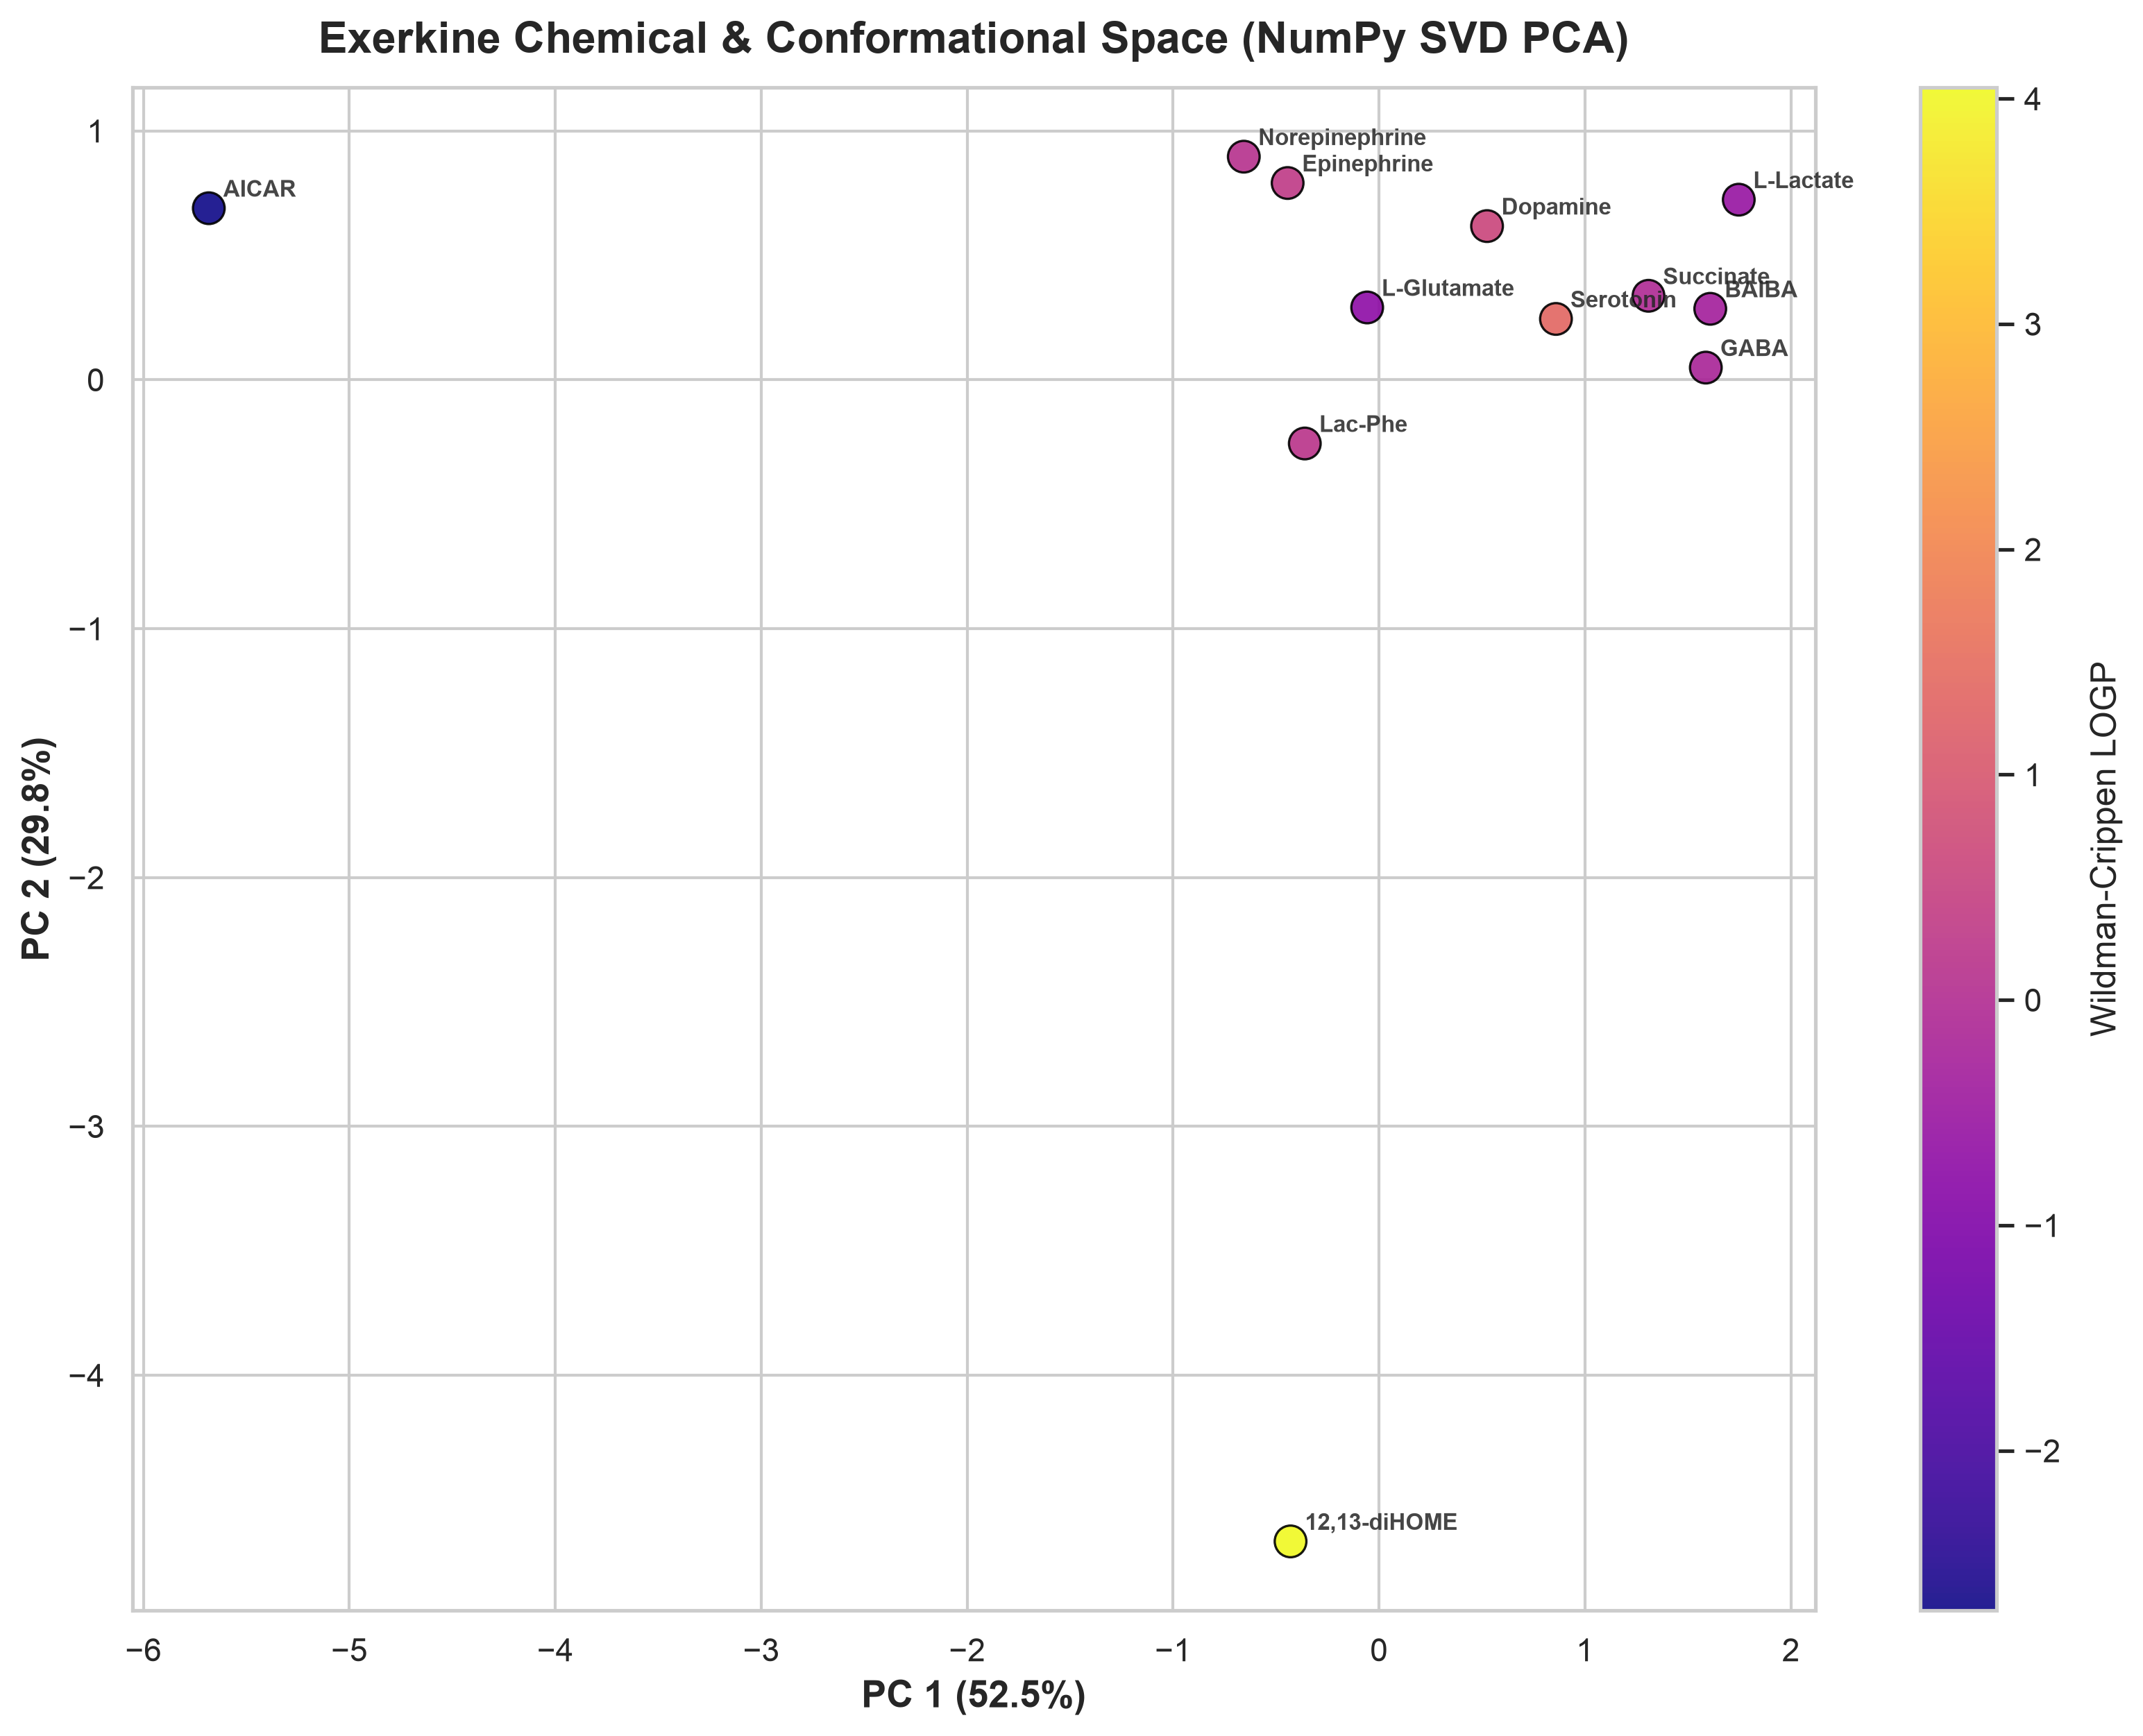

NumPy PCA complete across 12 exerkines and 8 features.
Renders saved to:
 - /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs/exerkine_pca_chemical_space.svg
 - /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs/exerkine_pca_chemical_space.png


In [35]:
# Required dependencies: pandas, numpy, matplotlib, seaborn (No sklearn/umap imports)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Master Descriptor Table
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
master_file = out_dir / "exerkine_master_1d_2d_3d_descriptors.csv"

if not master_file.exists():
    master_file = out_dir / "exerkine_computational_descriptors.csv"

df_master = pd.read_csv(master_file)

# 2. Select Relevant Numerical Features
candidate_features = [
    "mw_g_mol", "logp", "tpsa_ang2", "hbd", "hba", "rotatable_bonds", 
    "fraction_csp3", "formal_charge", "mean_radius_of_gyration", 
    "mean_asphericity", "mean_eccentricity", "mean_spherocity", 
    "mean_npmi1", "mean_npmi2"
]

feature_cols = [col for col in candidate_features if col in df_master.columns]

if len(feature_cols) < 3:
    raise ValueError(f"Insufficient numerical features found in {master_file.name} for projection.")

# 3. Pure Pandas Imputation & Standard Scaling: Z = (X - mu) / sigma
df_features = df_master[feature_cols].copy()
df_imputed = df_features.fillna(df_features.median())

X = df_imputed.values
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_std[X_std == 0] = 1.0  # Prevent division by zero for constant features
X_scaled = (X - X_mean) / X_std

# 4. Pure NumPy Singular Value Decomposition (SVD) for PCA: X_scaled = U * S * V^T
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)

# Compute Principal Component Scores (PC1, PC2)
pc_scores = X_scaled @ Vt.T[:, :2]

# Calculate Explained Variance Ratios
variances = (S ** 2) / (len(X_scaled) - 1)
total_var = np.sum(variances)
var_explained = (variances / total_var) * 100

df_master["Dim1"] = pc_scores[:, 0]
df_master["Dim2"] = pc_scores[:, 1]

dim_labels = (f"PC 1 ({var_explained[0]:.1f}%)", f"PC 2 ({var_explained[1]:.1f}%)")

# 5. Publication-Quality Render
sns.set_theme(style="whitegrid", font="sans-serif")
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=300)

hue_col = "logp" if "logp" in df_master.columns else "mw_g_mol"
scatter = ax.scatter(
    df_master["Dim1"],
    df_master["Dim2"],
    c=df_master[hue_col],
    cmap="plasma",
    s=120,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    zorder=3
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label(f"Wildman-Crippen {hue_col.upper()}", fontsize=12, labelpad=10)

for _, row in df_master.iterrows():
    name = str(row["metabolite"])
    clean_label = name.split(". ")[-1] if ". " in name else name
    ax.annotate(
        clean_label,
        (row["Dim1"], row["Dim2"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
        alpha=0.85,
        weight="semibold"
    )

ax.set_xlabel(dim_labels[0], fontsize=13, fontweight="bold")
ax.set_ylabel(dim_labels[1], fontsize=13, fontweight="bold")
ax.set_title("Exerkine Chemical & Conformational Space (NumPy SVD PCA)", fontsize=15, fontweight="bold", pad=12)

plt.tight_layout()

# Save High-Resolution Renders
out_svg = out_dir / "exerkine_pca_chemical_space.svg"
out_png = out_dir / "exerkine_pca_chemical_space.png"
fig.savefig(out_svg, format="svg", bbox_inches="tight")
fig.savefig(out_png, format="png", dpi=300, bbox_inches="tight")

plt.show()

print(f"NumPy PCA complete across {len(df_master)} exerkines and {len(feature_cols)} features.")
print(f"Renders saved to:\n - {out_svg}\n - {out_png}")

In [32]:
# Required dependencies: pandas, numpy, matplotlib, seaborn
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load previously generated projection
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
master_file = out_dir / "exerkine_master_1d_2d_3d_descriptors.csv"

df_master = pd.read_csv(master_file)

if "Dim1" not in df_master.columns or "Dim2" not in df_master.columns:
    raise ValueError("Projection dimensions (Dim1, Dim2) not found. Run Cell 10 first.")

# Extract 2D projection coordinates
X = df_master[["Dim1", "Dim2"]].values

# 2. Pure NumPy K-Means Implementation (Bypasses sklearn Cython errors)
def numpy_kmeans(X, k=4, max_iters=100, seed=20261019):
    """K-Means clustering utilizing pure NumPy broadcasting."""
    np.random.seed(seed)
    # Randomly initialize centroids from existing data points
    centroids = X[np.random.choice(X.shape[0], k, replace=False)]
    
    for _ in range(max_iters):
        # Euclidean distance from each point to each centroid
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)
        
        # Update centroids to the mean of assigned points
        new_centroids = np.array([
            X[labels == i].mean(axis=0) if np.sum(labels == i) > 0 else centroids[i] 
            for i in range(k)
        ])
        
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
        
    return labels, centroids

# 3. Execute Clustering (k=4 chemical families)
k_clusters = 4
labels, centroids = numpy_kmeans(X, k=k_clusters)

# Map labels back to DataFrame
df_master["Cluster"] = [f"Family {lbl + 1}" for lbl in labels]

# Save cluster assignments
df_master.to_csv(master_file, index=False)
df_master[["metabolite", "Dim1", "Dim2", "Cluster"]].to_csv(out_dir / "exerkine_cluster_assignments.csv", index=False)

# 4. Publication-Quality Render
sns.set_theme(style="whitegrid", font="sans-serif")
fig, ax = plt.subplots(figsize=(11, 8.5), dpi=300)

# Define distinct colors for the clusters
palette = sns.color_palette("Set2", n_colors=k_clusters)

# Plot Exerkines grouped by Cluster
sns.scatterplot(
    data=df_master,
    x="Dim1",
    y="Dim2",
    hue="Cluster",
    palette=palette,
    s=120,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    ax=ax,
    zorder=3
)

# Plot Centroids
ax.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    s=250,
    marker='X',
    edgecolor='black',
    linewidth=1.5,
    label='Centroids',
    zorder=4
)

# Annotate Exerkine Metabolite Names
for _, row in df_master.iterrows():
    name = str(row["metabolite"])
    clean_label = name.split(". ")[-1] if ". " in name else name
    ax.annotate(
        clean_label,
        (row["Dim1"], row["Dim2"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
        alpha=0.85,
        weight="semibold",
        zorder=5
    )

ax.set_xlabel("Projection Dimension 1", fontsize=13, fontweight="bold")
ax.set_ylabel("Projection Dimension 2", fontsize=13, fontweight="bold")
ax.set_title("Exerkine Chemical Families (NumPy K-Means Clustering)", fontsize=15, fontweight="bold", pad=12)

# Format Legend
handles, labels_leg = ax.get_legend_handles_labels()
ax.legend(handles, labels_leg, title="Chemical Clusters", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()

# Save High-Resolution Renders
out_svg = out_dir / "exerkine_kmeans_clusters.svg"
out_png = out_dir / "exerkine_kmeans_clusters.png"
fig.savefig(out_svg, format="svg", bbox_inches="tight")
fig.savefig(out_png, format="png", dpi=300, bbox_inches="tight")

plt.show()

print(f"Clustering complete. Identified {k_clusters} families across {len(df_master)} exerkines.")
print(f"Cluster assignments appended to: {master_file.name}")
print(f"Renders saved to:\n - {out_svg}\n - {out_png}")

FileNotFoundError: [Errno 2] No such file or directory: '/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs/exerkine_master_1d_2d_3d_descriptors.csv'

In [11]:
# Required dependencies: deepchem, rdkit, pandas, numpy
from pathlib import Path
import numpy as np
import pandas as pd
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors

# 1. Output Path Setup
out_dir = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/conformer_outputs")
out_dir.mkdir(parents=True, exist_ok=True)
csv_output_path = out_dir / "exerkine_50_moleculenet_gnn_embeddings.csv"

# 2. Unified 50 Exerkine Dataset using Raw Strings (r"...")
exerkines_50 = [
    ("12,13-diHOME", r"CCCCCC(O)C(O)CC=CCCCCCCCC(=O)O"),
    ("AICAR / acadesine vs ZMP", r"C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O)N)C(=O)N"),
    ("beta-aminoisobutyric acid (BAIBA)", r"CC(CN)C(=O)O"),
    ("2-hydroxybutyric acid / 2-hydroxybutyrate", r"CCC(C(=O)O)O"),
    ("3-hydroxybutyric acid / 3-OHB", r"CC(CC(=O)O)O"),
    ("Acetylcholine", r"CC(=O)OCC[N+](C)(C)C"),
    ("Dopamine", r"NCCc1ccc(O)c(O)c1"),
    ("Serotonin (5-hydroxytryptamine)", r"NCCc1c[nH]c2ccc(O)cc12"),
    ("Epinephrine (adrenaline)", r"CNCC(O)c1cc(O)c(O)cc1"),
    ("Norepinephrine (noradrenaline)", r"NCC(O)c1cc(O)c(O)cc1"),
    ("N-lactoyl-phenylalanine (Lac-Phe)", r"CC(O)C(=O)NC(Cc1ccccc1)C(=O)O"),
    ("Glycine", r"NCC(=O)O"),
    ("Alanine", r"CC(N)C(=O)O"),
    ("Valine", r"CC(C)C(N)C(=O)O"),
    ("Leucine", r"CC(C)CC(N)C(=O)O"),
    ("Isoleucine", r"CCC(C)C(N)C(=O)O"),
    ("Methionine", r"CSCCC(N)C(=O)O"),
    ("Proline", r"O=C(O)C1CCCN1"),
    ("Serine", r"N[C@@H](CO)C(=O)O"),
    ("Threonine", r"CC(O)[C@@H](N)C(=O)O"),
    ("Cysteine", r"N[C@@H](CS)C(=O)O"),
    ("Asparagine", r"N[C@@H](CC(N)=O)C(=O)O"),
    ("Glutamine", r"N[C@@H](CCC(N)=O)C(=O)O"),
    ("Phenylalanine", r"N[C@@H](Cc1ccccc1)C(=O)O"),
    ("Tyrosine", r"N[C@@H](Cc1ccc(O)cc1)C(=O)O"),
    ("Tryptophan", r"N[C@@H](Cc1c[nH]c2ccccc12)C(=O)O"),
    ("Lysine", r"NCCCC[C@@H](N)C(=O)O"),
    ("Arginine", r"N=C(N)NCCC[C@@H](N)C(=O)O"),
    ("Histidine", r"N[C@@H](Cc1cnc[nH]1)C(=O)O"),
    ("Aspartic acid / aspartate", r"N[C@@H](CC(=O)O)C(=O)O"),
    ("Glutamic acid / glutamate", r"N[C@@H](CCC(=O)O)C(=O)O"),
    ("Lactic acid / lactate", r"CC(O)C(=O)O"),
    ("Arachidonic acid (20:4 n-6)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("2-arachidonoylglycerol (2-AG)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)OC(CO)CO"),
    ("Anandamide (AEA)", r"CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Docosahexaenoic acid (DHA; 22:6 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)O"),
    ("N-docosahexaenoyl ethanolamide (DHEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Eicosapentaenoic acid (EPA; 20:5 n-3)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCC(=O)O"),
    ("N-eicosapentaenoyl ethanolamide (EPEA)", r"CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCC(=O)NCCO"),
    ("Pyruvic acid / pyruvate", r"CC(=O)C(=O)O"),
    ("D-glucose", r"C([C@@H]1[C@H]([C@@H]([C@H](C(O1)O)O)O)O)O"),
    ("Oleoylethanolamide (OEA)", r"CCCCCCCC/C=C\CCCCCCCC(=O)NCCO"),
    ("Palmitoleic acid (16:1 n-7)", r"CCCCCC/C=C\CCCCCCCC(=O)O"),
    ("Palmitic acid (16:0)", r"CCCCCCCCCCCCCCCC(=O)O"),
    ("Acetic acid / acetate", r"CC(=O)O"),
    ("Propionic acid / propionate", r"CCC(=O)O"),
    ("Butyric acid / butyrate", r"CCCC(=O)O"),
    ("Trimethylamine N-oxide (TMAO)", r"C[N+](C)(C)[O-]"),
    ("gamma-aminobutyric acid (GABA)", r"NCCCC(=O)O"),
    ("Succinate", r"C(CC(=O)O)C(=O)O"),
]

exerkine_smiles = [s for _, s in exerkines_50]
exerkine_names = [n.split(" / ")[0].split(" (")[0] for n, _ in exerkines_50]

# 3. Train GNN Model on MoleculeNet ESOL (if not already in namespace)
if 'pretrained_gnn' not in locals() and 'pretrained_gnn' not in globals():
    print("Pre-training DeepChem GraphConvModel on MoleculeNet ESOL physical property benchmark...")
    tasks_esol, datasets_esol, _ = dc.molnet.load_delaney(featurizer='GraphConv', reload=True)
    train_esol, _, _ = datasets_esol
    
    pretrained_gnn = dc.models.GraphConvModel(
        n_tasks=len(tasks_esol),
        batch_size=64,
        mode='regression',
        model_dir=str(out_dir / "gnn_pretrained_esol")
    )
    pretrained_gnn.fit(train_esol, nb_epoch=10)
    print("GNN pre-training complete.")

# 4. Featurize 50 Exerkines & Extract Latent Embeddings
print(f"Featurizing {len(exerkines_50)} exerkines...")
featurizer = dc.feat.ConvMolFeaturizer()
conv_mols = featurizer.featurize(exerkine_smiles)

valid_conv_mols, valid_names, valid_smiles = [], [], []
for mol, name, smi in zip(conv_mols, exerkine_names, exerkine_smiles):
    if mol is not None:
        valid_conv_mols.append(mol)
        valid_names.append(name)
        valid_smiles.append(smi)

exerkine_dataset = dc.data.NumpyDataset(X=np.array(valid_conv_mols), ids=valid_names)

# Extract 75-dimensional latent layer vectors
embeddings = pretrained_gnn.predict_embedding(exerkine_dataset)

# 5. Export Matrix to CSV and Assign Variables to Namespace
df_gnn_embeddings = pd.DataFrame(
    embeddings, 
    index=valid_names,
    columns=[f"GNN_Dim_{i+1}" for i in range(embeddings.shape[1])]
)
df_gnn_embeddings.insert(0, "SMILES", valid_smiles)
df_gnn_embeddings.to_csv(csv_output_path)

print(f"\nSuccessfully generated and exported latent embeddings matrix: {embeddings.shape}")
print(f"File written to: {csv_output_path}")
print("Variable 'embeddings' is now defined in namespace. Proceed to Cell 15.")

df_gnn_embeddings.iloc[:10, :6]

ModuleNotFoundError: No module named 'tensorflow.python'

In [ ]:
!pip uninstall -y tensorflow
!pip install --upgrade tensorflow

  Using cached tensorflow-2.22.0rc0-cp314-cp314-macosx_12_0_arm64.whl.metadata (4.5 kB)
Using cached tensorflow-2.22.0rc0-cp314-cp314-macosx_12_0_arm64.whl (245.6 MB)
